**Load Data**

In [113]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
import re
from scipy.stats import gmean
from sklearn.impute import KNNImputer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import StackingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import BaggingRegressor
import itertools
from sklearn.model_selection import cross_validate, KFold

In [114]:
wqi_data = pd.read_csv('quang_ninh_wqi_v3.csv')

# 1. Data Constructing


---






In [115]:
wqi_data.rename(columns={
    'Location': 'Location',
    'Sample ID': 'Sample_ID',
    'Month': 'Month',
    'Nhiệt độ (0C)': 'Temperature_C',
    'pH': 'pH',
    'DO mg/l': 'DO_mg_L',
    'Salinity': 'Salinity',
    'Turbidity': 'Turbidity',
    'TSS mg/l': 'TSS_mg_L',
    'COD mg/l': 'COD_mg_L',
    'BOD5 mg/l': 'BOD5_mg_L',
    'SO42-mg/l': 'SO4_mg_L',
    'NO3-mg/l': 'NO3_mg_L',
    'NO2-mg/l ': 'NO2_mg_L',
    'NH4+ mg/l': 'NH4_mg_L',
    'PO43- mg/l ': 'PO4_mg_L',
    'MBAS': 'MBAS',
    'Xianua': 'Cyanide',
    'Florua': 'Fluoride',
    'Cl - mg/l': 'Cl_mg_L',
    'Tổng dầu, mỡ mg/l': 'Total_Oil_Fat_mg_L',
    'Coliform MPN/100ml': 'Coliform_MPN_100ml',
    'E.Coli': 'EColi',
    'As mg/l': 'As_mg_L',
    'Hg mg/l': 'Hg_mg_L',
    'Pb mg/l': 'Pb_mg_L',
    'Cd mg/l': 'Cd_mg_L',
    'Fe mg/l': 'Fe_mg_L',
    'Mn': 'Mn',
    'Cu': 'Cu',
    'Ni': 'Ni',
    'Zn': 'Zn',
    'Cr': 'Cr',
    'Cr(VI)': 'CrVI',
    'Tổng phenol': 'Total_Phenol',
    'Tổng hoạt độ phóng xạ α': 'Total_Rad_Alpha',
    'Tổng hoạt độ phóng xạ β': 'Total_Rad_Beta',
    'Aldrin': 'Aldrin',
    'BHC': 'BHC',
    'Dieldrin': 'Dieldrin',
    'DDTs': 'DDTs',
    'Heptachlor & Heptachloreproxide': 'Heptachlor_Proxide',
    'TOC': 'TOC'
}, inplace=True)


Location: Sampling location

Sample_ID: Unique sample identifier

Month: Monitoring month

Temperature_C: Water temperature in Celsius

pH: pH level

DO_mg_L: Dissolved Oxygen in mg/L

Salinity: Salinity of water

Turbidity: Water turbidity

TSS_mg_L: Total Suspended Solids in mg/L

COD_mg_L: Chemical Oxygen Demand in mg/L

BOD5_mg_L: Biochemical Oxygen Demand over 5 days in mg/L

SO4_mg_L: Sulfate concentration in mg/L

NO3_mg_L: Nitrate concentration in mg/L

NO2_mg_L: Nitrite concentration in mg/L

NH4_mg_L: Ammonium concentration in mg/L

PO4_mg_L: Phosphate concentration in mg/L

MBAS: Surfactant content (MBAS method)

Cyanide: Cyanide concentration

Fluoride: Fluoride concentration

Cl_mg_L: Chloride concentration in mg/L

Total_Oil_Fat_mg_L: Total oil and fat content in mg/L

Coliform_MPN_100ml: Coliform bacteria count (MPN/100ml)

EColi: E. Coli bacteria count

As_mg_L: Arsenic concentration in mg/L

Hg_mg_L: Mercury concentration in mg/L

Pb_mg_L: Lead concentration in mg/L

Cd_mg_L: Cadmium concentration in mg/L

Fe_mg_L: Iron concentration in mg/L

Mn: Manganese concentration

Cu: Copper concentration

Ni: Nickel concentration

Zn: Zinc concentration

Cr: Chromium concentration

CrVI: Hexavalent Chromium concentration

Total_Phenol: Total phenol content

Total_Rad_Alpha: Total alpha radioactivity

Total_Rad_Beta: Total beta radioactivity

Aldrin: Aldrin pesticide concentration

BHC: BHC pesticide concentration

Dieldrin: Dieldrin pesticide concentration

DDTs: DDT and its derivatives concentration

Heptachlor_Proxide: Heptachlor & Heptachloreproxide concentration

TOC: Total Organic Carbon


In [116]:
wqi_data_droped = wqi_data.drop([
    'Location', 'Sample_ID', 'Month', 'Salinity', 'Turbidity', 'TSS_mg_L', 'SO4_mg_L', 'MBAS', 'Cyanide', 'Fluoride',
    'Cl_mg_L', 'Total_Oil_Fat_mg_L', 'Fe_mg_L', 'Mn', 'Cu', 'Ni', 'Zn', 'Total_Phenol',
    'Total_Rad_Alpha', 'Total_Rad_Beta'
], axis=1)

Drop some columns which don't impact to WQI scores

## 1.1 Missing Values


---
Identify and handle missing values.

In [117]:
wqi_data_filled = wqi_data_droped.replace('X', np.nan)
wqi_data_filled = wqi_data_droped.replace('x', np.nan)
wqi_data_filled.isnull().sum()

Temperature_C           0
pH                      0
DO_mg_L                 0
COD_mg_L                0
BOD5_mg_L               0
NO3_mg_L                0
NO2_mg_L                0
NH4_mg_L                0
PO4_mg_L                0
Coliform_MPN_100ml      0
EColi                 156
As_mg_L                 0
Hg_mg_L                 0
Pb_mg_L                 0
Cd_mg_L                 0
Cr                    156
CrVI                  156
Aldrin                766
BHC                   766
Dieldrin              766
DDTs                  766
Heptachlor_Proxide    766
TOC                   767
dtype: int64

Some cells contain 'x' instead of being empty, so the missing values were standardized and the number of missing values was calculated.


In [118]:
wqi_data_droped_v2 = wqi_data_filled.drop([
    'Cr', 'Aldrin', 'BHC', 'Dieldrin', 'DDTs', 'Heptachlor_Proxide', 'TOC'
], axis=1)

print(wqi_data_droped_v2.head())

  Temperature_C    pH DO_mg_L COD_mg_L BOD5_mg_L NO3_mg_L NO2_mg_L NH4_mg_L  \
0          21,5   7,9    8,23      9,8       4,5    0,747    0,064    0,154   
1          24,1  7,29    7,28     10,2       4,7    0,434     0,06    0,215   
2          28,4  6,81    7,18     19,2       7,2    0,492   <0,002    0,232   
3          26,7  7,42    6,25     15,2       5,4    0,266   <0,002    0,522   
4          17,1  6,31    7,44      5,3       1,8    0,865    0,023    0,096   

  PO4_mg_L Coliform_MPN_100ml EColi As_mg_L  Hg_mg_L  Pb_mg_L  Cd_mg_L CrVI  
0    0,024                400   NaN  0,0004  <0,0003  <0,0007  <0,0006  NaN  
1     0,01               2000   NaN  0,0005  <0,0003  <0,0007  <0,0006  NaN  
2    0,057               4500   NaN  0,0004  <0,0003   0,0018   0,0007  NaN  
3    0,098               7000   NaN  0,0006  <0,0003   0,0011  <0,0006  NaN  
4    0,048                 40   NaN  0,0003  <0,0003   0,0001  <0,0006  NaN  


Columns with about 75% missing values were removed.

In [119]:
wqi_data_cleaned = wqi_data_droped_v2[~wqi_data_droped_v2.apply(lambda row: row.astype(str).str.contains(r'\s*KCM\s*', regex=True).any(), axis=1)]

KCM: Value could not be measured; these records were removed from the dataset

## 1.2 Column, Cell data type conversion

In [120]:
def handle_less_than_numeric(val):
    # If the value is a string
    if isinstance(val, str):
        val = val.strip()
        # If it matches the pattern "<x" or "<x.y"
        match = re.fullmatch(r'<\s*([0-9,]*\.?[0-9]+)', val)
        if match:
            x_str = match.group(1).replace(',', '.')
            return float(x_str)
        # If it's a numeric string with comma or dot
        try:
            return float(val.replace(',', '.'))
        except ValueError:
            return val
    # If it's already a number, keep as is
    elif isinstance(val, (int, float)):
        return val
    # Other values remain unchanged
    return val

def convert_column_type(col):
    # Remove NaN to check
    non_na = col.dropna()

    # Check if all are numbers
    if non_na.apply(lambda x: isinstance(x, (int, float))).all():
        return col.astype(float)
    else:
        return col.astype('category')


# Apply the conversion to handle "<" and numeric strings
wqi_data_cleaned_v2 = wqi_data_cleaned.applymap(handle_less_than_numeric)

# Convert all to numeric (if not a number → NaN)
wqi_data_convert_cell = wqi_data_cleaned_v2.apply(convert_column_type)

print(wqi_data_convert_cell.head())

   Temperature_C    pH  DO_mg_L  COD_mg_L  BOD5_mg_L  NO3_mg_L  NO2_mg_L  \
0           21.5  7.90     8.23       9.8        4.5     0.747     0.064   
1           24.1  7.29     7.28      10.2        4.7     0.434     0.060   
2           28.4  6.81     7.18      19.2        7.2     0.492     0.002   
3           26.7  7.42     6.25      15.2        5.4     0.266     0.002   
4           17.1  6.31     7.44       5.3        1.8     0.865     0.023   

   NH4_mg_L  PO4_mg_L  Coliform_MPN_100ml  EColi  As_mg_L  Hg_mg_L  Pb_mg_L  \
0     0.154     0.024               400.0    NaN   0.0004   0.0003   0.0007   
1     0.215     0.010              2000.0    NaN   0.0005   0.0003   0.0007   
2     0.232     0.057              4500.0    NaN   0.0004   0.0003   0.0018   
3     0.522     0.098              7000.0    NaN   0.0006   0.0003   0.0011   
4     0.096     0.048                40.0    NaN   0.0003   0.0003   0.0001   

   Cd_mg_L  CrVI  
0   0.0006   NaN  
1   0.0006   NaN  
2   0.0007 

C:\Users\Admin\AppData\Local\Temp\ipykernel_7408\1738442683.py:33: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  wqi_data_cleaned_v2 = wqi_data_cleaned.applymap(handle_less_than_numeric)


Cells with values less than x will be converted to type x

In [121]:
wqi_data_filled.isnull().sum()

Temperature_C           0
pH                      0
DO_mg_L                 0
COD_mg_L                0
BOD5_mg_L               0
NO3_mg_L                0
NO2_mg_L                0
NH4_mg_L                0
PO4_mg_L                0
Coliform_MPN_100ml      0
EColi                 156
As_mg_L                 0
Hg_mg_L                 0
Pb_mg_L                 0
Cd_mg_L                 0
Cr                    156
CrVI                  156
Aldrin                766
BHC                   766
Dieldrin              766
DDTs                  766
Heptachlor_Proxide    766
TOC                   767
dtype: int64

There are 2 columns which include missing values that are EColi and CrVI

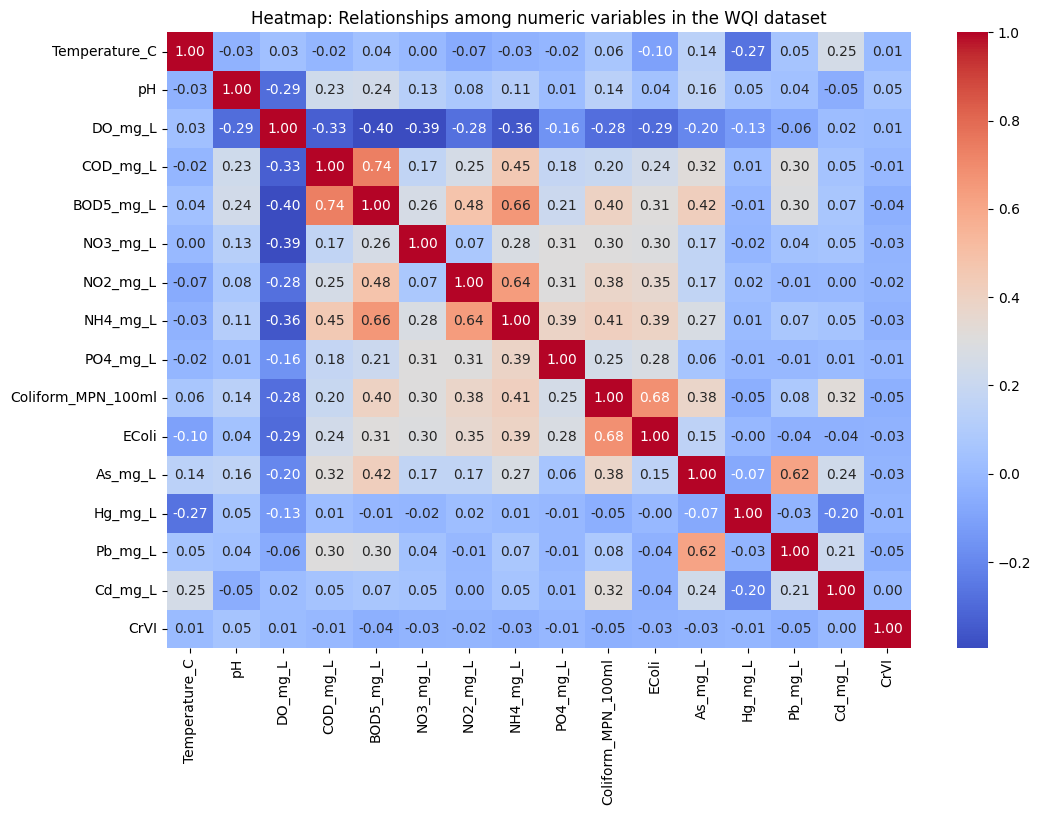

In [122]:
# Select numeric columns
numeric_cols = wqi_data_convert_cell.select_dtypes(include=['int64', 'float64']).columns
df_numeric = wqi_data_convert_cell[numeric_cols]

# Compute the correlation matrix
corr_matrix = df_numeric.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Heatmap: Relationships among numeric variables in the WQI dataset")
plt.show()

Because EColi and CrVI do not have any meaningful relationship with the other features, we cannot apply linear regression to predict them.

In [123]:
# List of numeric columns to impute
num_cols_to_impute = ['EColi', 'CrVI']

# List of numeric columns to impute
other_num_cols = [col for col in wqi_data_convert_cell.columns if col not in num_cols_to_impute]

# Create a copy to avoid modifying the original
df = wqi_data_convert_cell.copy()

# Select columns for KNN to work on
imputer = KNNImputer(n_neighbors=5)

df[num_cols_to_impute] = imputer.fit_transform(
    df[num_cols_to_impute + other_num_cols]
)[:, :len(num_cols_to_impute)]

wqi_data_convert_cell['EColi'] = df['EColi']
wqi_data_convert_cell['CrVI'] = df['CrVI']

I choose KNN because it better preserves the multivariate relationships between water quality parameters, making the imputed values more realistic. It also maintains the variance and distribution of the data, avoiding the loss of extreme values that are important for WQI. KNN improves machine learning model performance by providing context-aware imputations and is well-suited to the environmental similarity inherent in monitoring data. Overall, it leads to more accurate and reliable WQI predictions.

In [124]:
wqi_data_convert_cell.isnull().sum()

Temperature_C         0
pH                    0
DO_mg_L               0
COD_mg_L              0
BOD5_mg_L             0
NO3_mg_L              0
NO2_mg_L              0
NH4_mg_L              0
PO4_mg_L              0
Coliform_MPN_100ml    0
EColi                 0
As_mg_L               0
Hg_mg_L               0
Pb_mg_L               0
Cd_mg_L               0
CrVI                  0
dtype: int64

All missing values have already been handled.

## 1.3 Removing Inconsistent values and Outliers


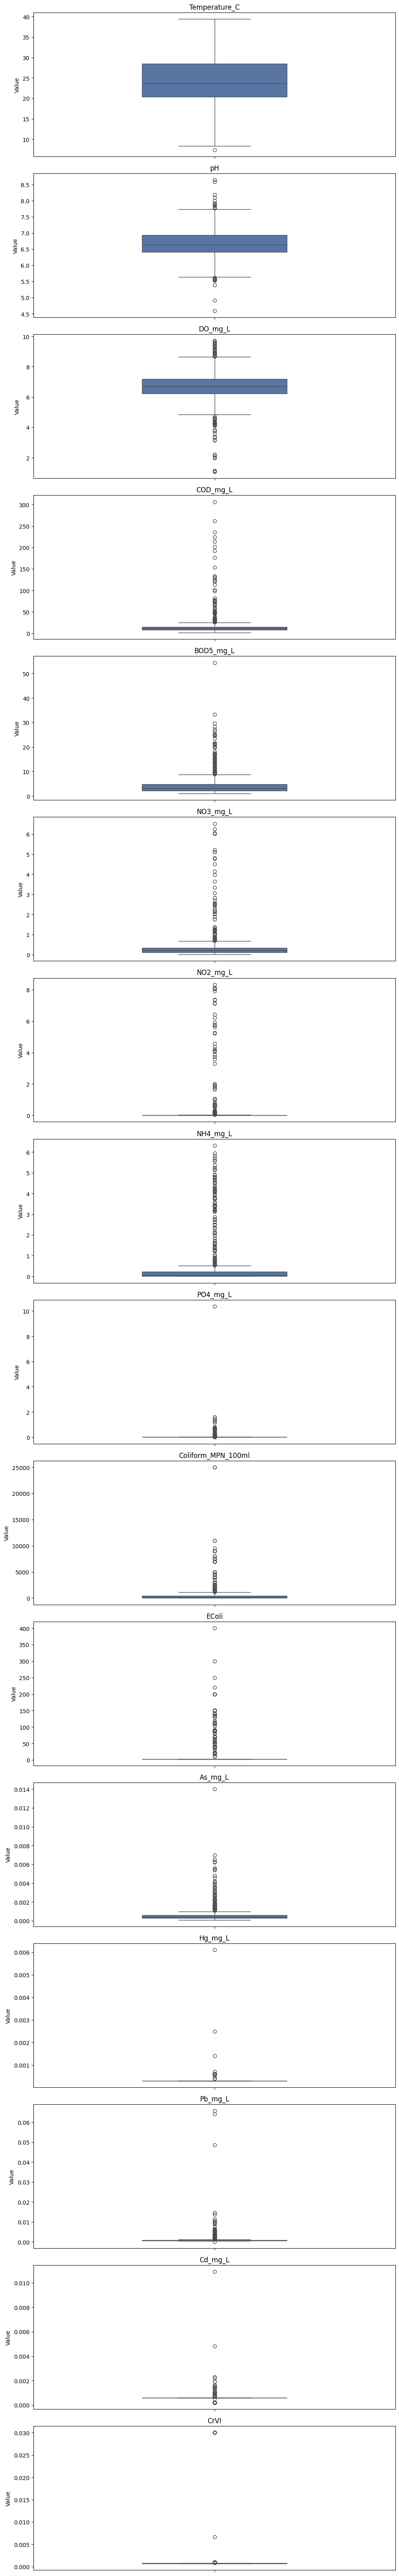

In [125]:
numeric_cols = wqi_data_convert_cell.select_dtypes(include='number').columns
n_cols = len(numeric_cols)

plt.figure(figsize=(10, 4 * n_cols))

for i, col in enumerate(numeric_cols):
    ax = plt.subplot(n_cols, 1, i + 1)
    sns.boxplot(
        y=wqi_data_convert_cell[col],
        ax=ax,
        color="#4c72b0",
        width=0.4
    )
    ax.set_title(col, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

Although there are many outliers in the data, they are likely to be false positive noise or valid extreme observations, so I decided not to handle them.

- Temperature (°C)
The temperature values show a moderately concentrated distribution, with most observations falling within a relatively narrow range around the median. The median temperature is approximately in the mid-20°C range, indicating generally warm water conditions. The interquartile range suggests moderate variability, reflecting some natural fluctuations in temperature across samples. A small number of lower-end outliers can be observed, which may correspond to measurements taken under cooler environmental conditions or at different times. Overall, the distribution indicates that water temperature is fairly stable, with no extreme variability that would suggest abnormal thermal conditions.

- pH
The pH values exhibit a relatively narrow distribution, with most observations clustered around the neutral range. The median pH is approximately between 6.5 and 7.0, indicating near-neutral water conditions that are generally suitable for aquatic life. The interquartile range is small, suggesting limited variability in pH across the sampled locations or time periods. However, several outliers are observed at both the lower and upper ends of the distribution. Lower-end outliers may indicate localized acidic conditions, while higher-end outliers suggest slightly alkaline environments in certain samples. Overall, the pH distribution reflects relatively stable water quality, with occasional deviations that may be influenced by local environmental or anthropogenic factors.

- DO (Dissolved Oxygen) (mg/L)
The dissolved oxygen (DO) values show a moderately concentrated distribution, with the majority of observations lying between approximately 6 and 7 mg/L. The median DO level is around 6.5 mg/L, indicating generally adequate oxygen availability to support aquatic organisms. The interquartile range suggests moderate variability in DO concentrations across the samples. Several lower-end outliers are present, which may reflect localized oxygen depletion due to organic pollution, high biological oxygen demand, or stagnant water conditions. A few higher-end outliers are also observed, possibly associated with increased aeration or photosynthetic activity. Overall, the DO distribution suggests that water quality is generally suitable for aquatic life, although some sites or periods may experience reduced oxygen levels that warrant further attention.

- COD (Chemical Oxygen Demand) (mg/L)
The COD values show a relatively wide distribution with a noticeable number of outliers at higher concentrations. Most observations are concentrated at low to moderate levels, indicating acceptable baseline organic content in the majority of samples. However, several extreme values are observed, suggesting episodes of elevated organic pollution at specific locations or time periods. These high COD outliers may be attributed to industrial discharge, sewage contamination, or agricultural runoff. This suggests that while the general water quality is acceptable in many samples, certain locations or periods may experience significant organic contamination that requires further investigation and management.

- BOD₅ (Biochemical Oxygen Demand) (mg/L)
The BOD₅ distribution is moderately spread, with the majority of values clustered at lower concentrations, indicating relatively low levels of biodegradable organic matter in most samples. The median value falls within an acceptable range for aquatic ecosystems. However, the presence of several high outliers indicates increased biodegradable organic matter in some samples. These elevated BOD₅ values may reflect localized organic pollution or wastewater influence from domestic or industrial sources. Such contamination could potentially lead to higher oxygen demand and stress on aquatic ecosystems if not properly managed.

- NO₃⁻ (Nitrate) (mg/L)
The NO₃⁻ concentrations exhibit a generally narrow distribution at low levels, with most values clustered near the lower end of the scale. This pattern suggests that nitrate levels are typically low and stable across most samples, indicating limited nutrient loading under normal conditions. However, several clear outliers extending to higher values are observed. These occasional spikes may occur due to agricultural runoff, fertilizer use, or other nutrient inputs from anthropogenic activities. Such elevated nitrate concentrations could pose a risk of eutrophication if they persist or increase over time, warranting continued monitoring and potential management interventions.

- NO₂⁻ (Nitrite) (mg/L)
The NO₂⁻ values show a very narrow distribution, with most observations concentrated close to zero, indicating minimal nitrite presence in the majority of water samples. The median and interquartile range are both very low, reflecting stable nitrogen cycling processes in most locations. However, several clear outliers appear at higher concentrations, deviating significantly from the typical baseline. This indicates that nitrite levels are generally low and stable in most water samples, while occasional spikes may occur due to incomplete nitrification processes or localized pollution sources. Although infrequent, these elevated values may pose potential risks to aquatic life and should be monitored closely.

- NH₄⁺ (Ammonium) (mg/L)
The NH₄⁺ distribution is relatively narrow around low concentrations, with most values clustered near the baseline level. The median ammonium concentration is low, indicating minimal ammonia pollution in the majority of samples. However, a noticeable number of high outliers are present, extending well beyond the upper whisker of the boxplot. This suggests that ammonium concentrations are typically low across most samples, indicating generally good water quality. Nevertheless, the presence of extreme values may reflect episodic inputs from wastewater discharge, agricultural runoff, or organic matter decomposition, which could negatively impact water quality if persistent.

- PO₄³⁻ (Phosphate) (mg/L)
The PO₄³⁻ values are highly concentrated near zero, with a very narrow interquartile range, indicating minimal phosphate enrichment in most water samples. The median concentration is very low, suggesting limited anthropogenic phosphorus inputs under typical conditions. A few distinct outliers at higher concentrations are observed, indicating sporadic increases in phosphate levels at certain locations or times. These elevated values may be associated with fertilizer runoff or domestic wastewater inputs from urban or agricultural areas. Such phosphate spikes could contribute to eutrophication if they occur frequently, although overall phosphate concentrations remain low in most samples, suggesting limited nutrient enrichment under normal conditions.

- Coliform (MPN/100 mL)
The Coliform values exhibit a highly skewed distribution with a large number of extreme outliers extending far beyond the upper whisker. The median and interquartile range suggest that baseline coliform levels are relatively controlled in many samples. However, while most samples show relatively low concentrations, several observations reach very high levels, indicating significant variability in microbial contamination across the dataset. These elevated values suggest that certain locations or periods may be strongly affected by fecal pollution or untreated wastewater inputs. Such contamination poses potential risks to water quality and public health, necessitating targeted intervention and continuous microbiological monitoring.

- E. coli (MPN/100 mL)
The E. coli distribution is strongly right-skewed, with the majority of values clustered near zero and multiple high outliers. The median E. coli count is very low, suggesting that most water samples are relatively free from fecal contamination under baseline conditions. This pattern indicates that E. coli contamination is generally low in most samples, but sporadic contamination events occur. Such peaks may be associated with sewage discharge, surface runoff, or animal waste from agricultural activities. These findings highlight the need for regular microbiological monitoring to ensure water safety and protect public health.

- As (Arsenic) (mg/L)
The arsenic (As) concentrations show a narrow distribution at low levels, with the median value close to zero or very minimal. Most samples fall within a tight interquartile range, indicating that arsenic contamination is limited in the majority of locations. However, a small number of higher outliers are present, suggesting occasional exceedances of typical background levels. This suggests that arsenic levels are typically low and stable in most water samples. The presence of outliers indicates occasional exceedances that may be linked to geological sources or anthropogenic activities such as mining or industrial processes. These elevated arsenic concentrations warrant attention due to potential long-term health risks associated with chronic exposure.

- Hg (Mercury) (mg/L)
The distribution of Hg concentrations is highly skewed, with the majority of values clustered very close to zero, indicating generally low background levels in most water samples. The interquartile range is extremely narrow, suggesting minimal mercury presence under typical environmental conditions. However, several distinct outliers are observed at higher concentrations, deviating markedly from the baseline. These outliers suggest sporadic mercury contamination events, which may be associated with localized pollution sources or episodic discharges from industrial activities. Although typical Hg levels appear low and stable, the presence of extreme values is environmentally significant and should not be overlooked due to mercury's high toxicity even at low concentrations.

- Pb (Lead) (mg/L)
Pb exhibits a wider distribution compared to Hg, with a slightly higher median and a more dispersed interquartile range. The central tendency indicates that lead is present at detectable levels in many samples, though concentrations remain generally low. A substantial number of outliers are present, including several extreme values far above the upper whisker. This pattern indicates considerable variability in lead concentrations across sampling locations or time periods. The frequent occurrence of high outliers suggests that lead pollution is not isolated but may be influenced by multiple anthropogenic sources such as industrial effluents, traffic-related runoff, or legacy contamination. This variability highlights Pb as a critical parameter requiring close monitoring.

- Cd (Cadmium) (mg/L)
The Cd box plot shows a narrow central distribution with most values concentrated at low concentrations, similar to Hg. The median cadmium level is very low, indicating minimal cadmium presence in the majority of water samples. Nevertheless, several pronounced outliers are visible, including at least one extreme value significantly higher than the rest of the dataset. This indicates that while cadmium levels are generally low and stable in most samples, occasional spikes occur. Such spikes may reflect localized contamination or abnormal environmental conditions from industrial sources or mining activities. Given the high ecological and health risks associated with cadmium, these outliers are of particular concern despite the low median concentration.

- Cr(VI) (Hexavalent Chromium) (mg/L)
The distribution of Cr(VI) concentrations is highly right-skewed, with the vast majority of values tightly clustered near zero, indicating generally low and stable background levels in most water samples. The interquartile range is very narrow, suggesting limited variability under normal conditions. However, several distinct outliers are observed, including at least one extreme value that is markedly higher than the rest of the dataset. These outliers indicate sporadic but significant chromium contamination events, potentially linked to localized industrial activities or accidental discharges from electroplating, leather tanning, or chemical manufacturing. Despite the low median concentration, the presence of extreme Cr(VI) values is environmentally critical due to the high toxicity of hexavalent chromium, warranting careful monitoring and targeted management.

## 1.3 Caculate the WQI output

---

The WQI was calculated using the formula provided by the Vietnamese government.

In [126]:
# 1. Configure the BP threshold values for each metal
# The order of values corresponds to i = 1, 2, 3, 4, 5
metal_configs = {
    'As_mg_L':   [0.01, 0.02, 0.05, 0.1,  0.1], 
    'Cd_mg_L':   [0.005, 0.005, 0.008, 0.01, 0.1],
    'Pb_mg_L':   [0.02, 0.02, 0.04, 0.05, 0.5],
    'CrVI': [0.01, 0.02, 0.04, 0.05, 0.1],
    'Cu':   [0.1, 0.2, 0.5, 1.0, 2.0],
    'Zn':   [0.5, 1.0, 1.5, 2.0, 3.0],
    'Hg_mg_L':   [0.001, 0.001, 0.0015, 0.002, 0.01]
}

# q values corresponding to levels i from 1 to 5
q_values = [100, 75, 50, 25, 10]

# 2. General WQI calculation function
def calculate_wqi_generic(cp, bp_list):
    if pd.isna(cp) or not isinstance(cp, (int, float)):
        return np.nan

    # If Cp is better than or equal to the highest standard level (level 1)
    if cp <= bp_list[0]:
        return q_values[0]

    # If Cp is worse than or equal to the lowest standard level (level 5)
    if cp >= bp_list[4]:
        return q_values[4]

    # Find the interval to apply Formula 1
    for i in range(len(bp_list) - 1):
        bp_i, bp_i1 = bp_list[i], bp_list[i+1]
        q_i, q_i1 = q_values[i], q_values[i+1]

        if bp_i <= cp <= bp_i1:
            # Case when bp_i == bp_i1 (like Pb, Hg at levels 1-2)
            if cp == bp_i and i != 0:
                return cp
            if cp == bp_i1 and i != 4:
                return cp

            wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
            return round(wqi, 2)

# 3. Loop to automatically calculate for all columns in the configuration
for metal, bp_points in metal_configs.items():
    if metal in wqi_data_convert_cell.columns:
        new_col_name = f'WQI_{metal.split()[0]}'
        wqi_data_convert_cell[new_col_name] = wqi_data_convert_cell[metal].apply(
            lambda x: calculate_wqi_generic(x, bp_points)
        )

# Display the updated DataFrame with new WQI columns
print(wqi_data_convert_cell.head())

   Temperature_C    pH  DO_mg_L  COD_mg_L  BOD5_mg_L  NO3_mg_L  NO2_mg_L  \
0           21.5  7.90     8.23       9.8        4.5     0.747     0.064   
1           24.1  7.29     7.28      10.2        4.7     0.434     0.060   
2           28.4  6.81     7.18      19.2        7.2     0.492     0.002   
3           26.7  7.42     6.25      15.2        5.4     0.266     0.002   
4           17.1  6.31     7.44       5.3        1.8     0.865     0.023   

   NH4_mg_L  PO4_mg_L  Coliform_MPN_100ml  ...  As_mg_L  Hg_mg_L  Pb_mg_L  \
0     0.154     0.024               400.0  ...   0.0004   0.0003   0.0007   
1     0.215     0.010              2000.0  ...   0.0005   0.0003   0.0007   
2     0.232     0.057              4500.0  ...   0.0004   0.0003   0.0018   
3     0.522     0.098              7000.0  ...   0.0006   0.0003   0.0011   
4     0.096     0.048                40.0  ...   0.0003   0.0003   0.0001   

   Cd_mg_L     CrVI  WQI_As_mg_L  WQI_Cd_mg_L  WQI_Pb_mg_L  WQI_CrVI  \
0   0.00

In [127]:
def calculate_wqi_do(do_measured, temp):
    """
    Calculate the WQI for the DO parameter based on temperature and dissolved oxygen concentration.
    do_measured: Column 'DO mg/L'
    temp: Column 'Temperature (°C)'
    """
    if pd.isna(do_measured) or pd.isna(temp) or not isinstance(do_measured, (int, float)) or not isinstance(temp, (int, float)):
        return np.nan

    # Step 1: Calculate saturated DO (DO_saturated) based on temperature T
    # Formula: 14.652 - 0.41022*T + 0.0079910*T^2 - 0.0000777747*T^3
    do_sat = (14.652 - 0.41022 * temp +
              0.0079910 * (temp**2) -
              0.000077774 * (temp**3))

    # Calculate DO % saturation (Cp)
    cp = (do_measured / do_sat) * 100

    # Table 3: Standard values of BPi and qi for DO % saturation
    bp_do = [20, 50, 75, 88, 112, 125, 150, 200]
    q_do = [25, 50, 75, 100, 100, 75, 50, 25]

    # Check if Cp exactly matches any breakpoint values in the table
    for i, bp_val in enumerate(bp_do):
        if round(cp, 2) == bp_val:
            return q_do[i]

    if cp < 20 or cp > 200:
        return 10

    if 88 <= cp <= 112:
        return 100

    # Case 20 < Cp < 88: Use Formula 2
    if 20 < cp < 88:
        # Determine the interval i
        for i in range(0, 3): # Only consider breakpoints 20, 50, 75, 88
            bp_i, bp_i1 = bp_do[i], bp_do[i+1]
            q_i, q_i1 = q_do[i], q_do[i+1]

            if bp_i < cp < bp_i1:
                # Formula 2: WQI = [(qi+1 - qi) / (BPi+1 - BPi)] * (Cp - BPi) + qi
                wqi = ((q_i1 - q_i) / (bp_i1 - bp_i)) * (cp - bp_i) + q_i
                return round(wqi, 2)

    # Case 112 < Cp < 200: Use Formula 1
    if 112 < cp < 200:
        # Determine the interval i (breakpoints 112, 125, 150, 200)
        for i in range(4, 7):
            bp_i, bp_i1 = bp_do[i], bp_do[i+1]
            q_i, q_i1 = q_do[i], q_do[i+1]

            if bp_i < cp < bp_i1:
                # Formula 1: WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
                wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
                return round(wqi, 2)


# Apply to DataFrame
wqi_data_convert_cell['WQI_DO'] = wqi_data_convert_cell.apply(
    lambda row: calculate_wqi_do(row['DO_mg_L'], row['Temperature_C']), axis=1
)

print(wqi_data_convert_cell[['DO_mg_L', 'Temperature_C', 'WQI_DO']].head())

   DO_mg_L  Temperature_C  WQI_DO
0     8.23           21.5  100.00
1     7.28           24.1   99.07
2     7.18           28.4  100.00
3     6.25           26.7   82.61
4     7.44           17.1   80.04


In [128]:
def calculate_wqi_ph(cp):
    """
    Calculate the WQI for the pH parameter based on Table 4 and interpolation formulas.
    cp: observed pH value.
    """

    if pd.isna(cp) or not isinstance(cp, (int, float)):
        return np.nan

    # Table 4: Regulations for BPi and qi values for pH
    # i=1: <5.5 (q=10), i=2: 5.5 (q=50), i=3: 6 (q=100)
    # i=4: 8.5 (q=100), i=5: 9 (q=50), i=6: >9 (q=10)

    # 1. Case when the value is outside the range or exactly at an extreme boundary
    if cp < 5.5 or cp > 9:
        return 10


    # 2. Case when the value exactly matches the breakpoint values in the table
    if cp == 5.5: return 50
    if cp == 6.0: return 100
    if cp == 8.5: return 100
    if cp == 9.0: return 50

    # 3. Case when 5.5 < pH < 6: Use Formula 2
    if 5.5 < cp < 6:
        # i=2 (BPi=5.5, qi=50); i+1=3 (BPi+1=6, qi+1=100)
        bp_i, bp_i1 = 5.5, 6.0
        q_i, q_i1 = 50, 100
        # WQI = [(qi+1 - qi) / (BPi+1 - BPi)] * (Cp - BPi) + qi
        wqi = ((q_i1 - q_i) / (bp_i1 - bp_i)) * (cp - bp_i) + q_i
        return round(wqi, 2)

    # 4. Case when 6 <= pH <= 8.5: WQI = 100
    if 6 <= cp <= 8.5:
        return 100

    # 5. Case when 8.5 < pH < 9: Use Formula 1
    if 8.5 < cp < 9:
        # i=4 (BPi=8.5, qi=100); i+1=5 (BPi+1=9, qi+1=50)
        bp_i, bp_i1 = 8.5, 9.0
        q_i, q_i1 = 100, 50
        # WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
        wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
        return round(wqi, 2)

# Apply to the entire data in the 'pH' column
wqi_data_convert_cell['WQI_ph'] = wqi_data_convert_cell['pH'].apply(calculate_wqi_ph)

# Display the check results
print(wqi_data_convert_cell[['pH', 'WQI_ph']].head())

     pH  WQI_ph
0  7.90   100.0
1  7.29   100.0
2  6.81   100.0
3  7.42   100.0
4  6.31   100.0


In [129]:
# 1. Set up the BP benchmark values table for each parameter
# Corresponding q values order: 100, 75, 50, 25, 10
q_values = [100, 75, 50, 25, 10]

params_config = {
    'BOD5_mg_L':          [4, 6, 15, 25, 50],
    'COD_mg_L':           [10, 15, 30, 50, 150],
    'TOC':                [4, 6, 15, 25, 50],
    'NH4_mg_L':          [0.3, 0.3, 0.6, 0.9, 5], 
    'NO3_mg_L':           [2, 5, 10, 15, 15],  
    'PO4_mg_L':         [0.1, 0.2, 0.3, 0.5, 4],
    'Coliform_MPN_100ml': [2500, 5000, 7500, 10000, 10000],
    'EColi':             [20, 50, 100, 200, 200]
}

# 2. General function to calculate WQI SI (using Formula 1)
def calculate_wqi_formula1(cp, bp_list):
    if pd.isna(cp): return np.nan

    # Case when the value matches a boundary or exceeds an extreme limit
    if cp <= bp_list[0]: return q_values[0]
    if cp >= bp_list[4]: return q_values[4]

    # Check if the Cp value exactly matches the BPi benchmark point
    for i, bp_val in enumerate(bp_list):
        if cp == bp_val:
            return q_values[i]

    # Apply Formula 1 for the intervals
    for i in range(len(bp_list) - 1):
        bp_i, bp_i1 = bp_list[i], bp_list[i+1]
        q_i, q_i1 = q_values[i], q_values[i+1]

        if bp_i < cp < bp_i1:
            # WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
            wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
            return round(wqi, 2)

# 3. Loop automatically to calculate for columns (Except NO2- handled separately)
for param, bp_points in params_config.items():
    if param in wqi_data_convert_cell.columns:
        # Create a new column name, e.g., WQI_BOD5, WQI_NH4...
        new_col = f"WQI_{param.replace('+', '').replace('-', '')}"
        wqi_data_convert_cell[new_col] = wqi_data_convert_cell[param].apply(
            lambda x: calculate_wqi_formula1(x, bp_points)
        )

# 4. Handle NO2- separately (Because the table only has 2 levels: <=0.05 and >0.05)
if 'NO2_mg_L' in wqi_data_convert_cell.columns:
    wqi_data_convert_cell['WQI_NO2_mg_L'] = wqi_data_convert_cell['NO2_mg_L'].apply(
        lambda x: 100 if x <= 0.05 else 10 if x > 0.05 else np.nan
    )

# Display the results of the newly created WQI columns
wqi_cols = [c for c in wqi_data_convert_cell.columns if c.startswith('WQI_')]
print(wqi_data_convert_cell[wqi_cols].head())

   WQI_As_mg_L  WQI_Cd_mg_L  WQI_Pb_mg_L  WQI_CrVI  WQI_Hg_mg_L  WQI_DO  \
0        100.0        100.0        100.0     100.0        100.0  100.00   
1        100.0        100.0        100.0     100.0        100.0   99.07   
2        100.0        100.0        100.0     100.0        100.0  100.00   
3        100.0        100.0        100.0     100.0        100.0   82.61   
4        100.0        100.0        100.0     100.0        100.0   80.04   

   WQI_ph  WQI_BOD5_mg_L  WQI_COD_mg_L  WQI_NH4_mg_L  WQI_NO3_mg_L  \
0   100.0          93.75        100.00         100.0         100.0   
1   100.0          91.25         99.00         100.0         100.0   
2   100.0          71.67         68.00         100.0         100.0   
3   100.0          82.50         74.67          56.5         100.0   
4   100.0         100.00        100.00         100.0         100.0   

   WQI_PO4_mg_L  WQI_Coliform_MPN_100ml  WQI_EColi  WQI_NO2_mg_L  
0         100.0                   100.0     100.00           

In [130]:
wqi_data_convert_cell.isnull().sum()

Temperature_C             0
pH                        0
DO_mg_L                   0
COD_mg_L                  0
BOD5_mg_L                 0
NO3_mg_L                  0
NO2_mg_L                  0
NH4_mg_L                  0
PO4_mg_L                  0
Coliform_MPN_100ml        0
EColi                     0
As_mg_L                   0
Hg_mg_L                   0
Pb_mg_L                   0
Cd_mg_L                   0
CrVI                      0
WQI_As_mg_L               0
WQI_Cd_mg_L               0
WQI_Pb_mg_L               0
WQI_CrVI                  0
WQI_Hg_mg_L               0
WQI_DO                    0
WQI_ph                    0
WQI_BOD5_mg_L             0
WQI_COD_mg_L              0
WQI_NH4_mg_L              0
WQI_NO3_mg_L              0
WQI_PO4_mg_L              0
WQI_Coliform_MPN_100ml    0
WQI_EColi                 0
WQI_NO2_mg_L              0
dtype: int64

In [131]:
def calculate_final_vn_wqi(row):
    # 1. Grouping of parameters
    group_i_cols = ['WQI_ph']

    # Group II: Pesticides
    group_ii_cols = [col for col in row.index if col.startswith('WQI_') and
                     any(p in col for p in ['Aldrin', 'DDTs', 'BHC', 'Dieldrin'])]

    # Group III: Heavy metals
    group_iii_cols = ['WQI_As_mg_L', 'WQI_Cd_mg_L', 'WQI_Pb_mg_L', 'WQI_CrVI', 'WQI_Cu', 'WQI_Zn', 'WQI_Hg_mg_L']

    # Group IV: Organic & Nutrients (Mandatory - at least 3 parameters)
    group_iv_cols = ['WQI_DO', 'WQI_BOD5_mg_L', 'WQI_COD_mg_L', 'WQI_TOC', 'NH4_mg_L', 'NO3_mg_L', 'WQI_NO2_mg_L', 'WQI_PO4_mg_L']

    # Group V: Microbiological
    group_v_cols = ['WQI_Coliform_MPN_100ml', 'WQI_EColi']

    # 2. Check calculation conditions
    # - Group IV is mandatory and must have at least 3 parameters
    valid_iv = [row[c] for c in group_iv_cols if c in row.index and pd.notna(row[c])]
    if len(valid_iv) < 3:
        return np.nan # Not enough conditions to calculate VN_WQI
    # - At least 3 out of 5 parameter groups must be available 
    available_groups = 0
    groups_data = {}

    for g_name, cols in [('I', group_i_cols), ('II', group_ii_cols),
                         ('III', group_iii_cols), ('IV', group_iv_cols), ('V', group_v_cols)]:
        valid_vals = [row[c] for c in cols if c in row.index and pd.notna(row[c])]
        if valid_vals:
            available_groups += 1
            groups_data[g_name] = valid_vals

    if available_groups < 3:
        return np.nan

    # 3. Calculate the average value for each group
    # Group I: WQI_I
    wqi_1 = groups_data['I'][0] if 'I' in groups_data else 100

    # Group II & III: Geometric Mean
    wqi_2_val = gmean(groups_data['II']) if 'II' in groups_data else 100
    wqi_3_val = gmean(groups_data['III']) if 'III' in groups_data else 100

    # Group IV & V: Arithmetic Mean
    wqi_4_avg = np.mean(groups_data['IV'])
    wqi_5_avg = np.mean(groups_data['V']) if 'V' in groups_data else np.nan

    # 4. Apply Formula 3
    # Square root component of groups IV and V
    if not np.isnan(wqi_5_avg):
        bracket_term = np.sqrt(wqi_4_avg * wqi_5_avg)
    else:
        bracket_term = wqi_4_avg # If group V is missing, use only group IV
    final_wqi = (wqi_1 / 100) * (wqi_2_val / 100) * (wqi_3_val / 100) * bracket_term

    return round(final_wqi, 0)

# Apply calculation to the entire DataFrame
wqi_data_convert_cell['VN_WQI'] = wqi_data_convert_cell.apply(calculate_final_vn_wqi, axis=1)

# Display the final results
print(wqi_data_convert_cell[['VN_WQI']].head())

   VN_WQI
0    76.0
1    71.0
2    69.0
3    56.0
4    83.0


In [132]:
wqi_data_convert_cell.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1101 entries, 0 to 1109
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature_C           1101 non-null   float64
 1   pH                      1101 non-null   float64
 2   DO_mg_L                 1101 non-null   float64
 3   COD_mg_L                1101 non-null   float64
 4   BOD5_mg_L               1101 non-null   float64
 5   NO3_mg_L                1101 non-null   float64
 6   NO2_mg_L                1101 non-null   float64
 7   NH4_mg_L                1101 non-null   float64
 8   PO4_mg_L                1101 non-null   float64
 9   Coliform_MPN_100ml      1101 non-null   float64
 10  EColi                   1101 non-null   float64
 11  As_mg_L                 1101 non-null   float64
 12  Hg_mg_L                 1101 non-null   float64
 13  Pb_mg_L                 1101 non-null   float64
 14  Cd_mg_L                 1101 non-null   float

In [133]:
final_data = wqi_data_convert_cell.copy()

Intermediate WQI sub-index columns, which were used solely for calculating the final VN_WQI score according to the Vietnamese government's formula, have been removed. 
The final dataset retains only the raw water quality parameters (input features) and the computed VN_WQI (target variable), allowing machine learning models to learn direct relationships between measurements and the water quality index. 
In future studies, WQI sub-indices could also be used as input features instead of the raw parameters.

In [134]:
numeric_df = final_data.select_dtypes(include='number')

stats_table = pd.DataFrame({
    'Minimum': numeric_df.min(),
    'Maximum': numeric_df.max(),
    'Mean': numeric_df.mean(),
    'Median': numeric_df.median(),
    'Std. Deviation': numeric_df.std()
})

stats_table = stats_table.round(3)

stats_table.style.format("{:.3f}") \
    .set_caption("Descriptive Statistics of Water Quality Parameters") \
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '14px'), ('font-weight', 'bold')]},
        {'selector': 'th',
         'props': [('background-color', "#000000"),
                   ('font-weight', 'bold'),
                   ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('text-align', 'center')]}
    ])

,Minimum,Maximum,Mean,Median,Std. Deviation
Temperature_C,7.400,39.400,24.222,23.600,4.843
pH,4.590,8.640,6.685,6.640,0.444
DO_mg_L,1.080,9.700,6.703,6.720,0.997
COD_mg_L,1.500,306.400,15.604,11.300,23.158
BOD5_mg_L,1.000,54.400,4.280,3.100,4.192
NO3_mg_L,0.008,6.528,0.345,0.214,0.638
NO2_mg_L,0.002,8.337,0.185,0.002,0.951
NH4_mg_L,0.010,6.321,0.399,0.054,1.018
PO4_mg_L,0.010,10.365,0.051,0.010,0.336
Coliform_MPN_100ml,3.000,25000.000,766.685,150.000,1885.311


Final dataset description: 
- Water quality data from Quang Ninh Province, Vietnam, were collected from 2019 to 2021 at multiple monitoring stations covering rivers, lakes, and coastal areas, including key sites near Ha Long Bay, a UNESCO World Natural Heritage site. The dataset includes monthly and bimonthly measurements of physical, chemical, microbiological, and heavy metal parameters to provide a comprehensive assessment of water quality in the province.
- The monitored water quality variables comprised: Temperature (°C), pH, Dissolved Oxygen (DO, mg/L), Biochemical Oxygen Demand over 5 days (BOD₅, mg/L), Chemical Oxygen Demand (COD, mg/L), Nitrate (NO₃, mg/L), Nitrite (NO₂, mg/L), Ammonium (NH₄⁺, mg/L), Phosphate (PO₄³⁻, mg/L), Coliform (MPN/100 mL), E. coli, and trace heavy metals (As, Hg, Pb, Cd, CrVI, mg/L).
- The descriptive statistics of the observed water quality parameters and WQI are summarized in Table 1. Parameters such as Coliform, COD, and BOD₅ exhibited considerable variability, reflecting differences in point and non-point sources of pollution, as well as seasonal hydro-climatic influences. In contrast, parameters such as pH and trace metals showed relatively stable values over the monitoring period.
- The Water Quality Index (WQI) was calculated for each monitoring station using standard guidelines issued by the Ministry of Natural Resources and Environment (MONRE) of Vietnam. The WQI provides an aggregated assessment of water quality, allowing classification into five categories: excellent (91–100), good (76–90), fair (51–75), poor (26–50), and very poor (0–25).

# 2. Exploratory Data Analysis


---

KeyboardInterrupt: 

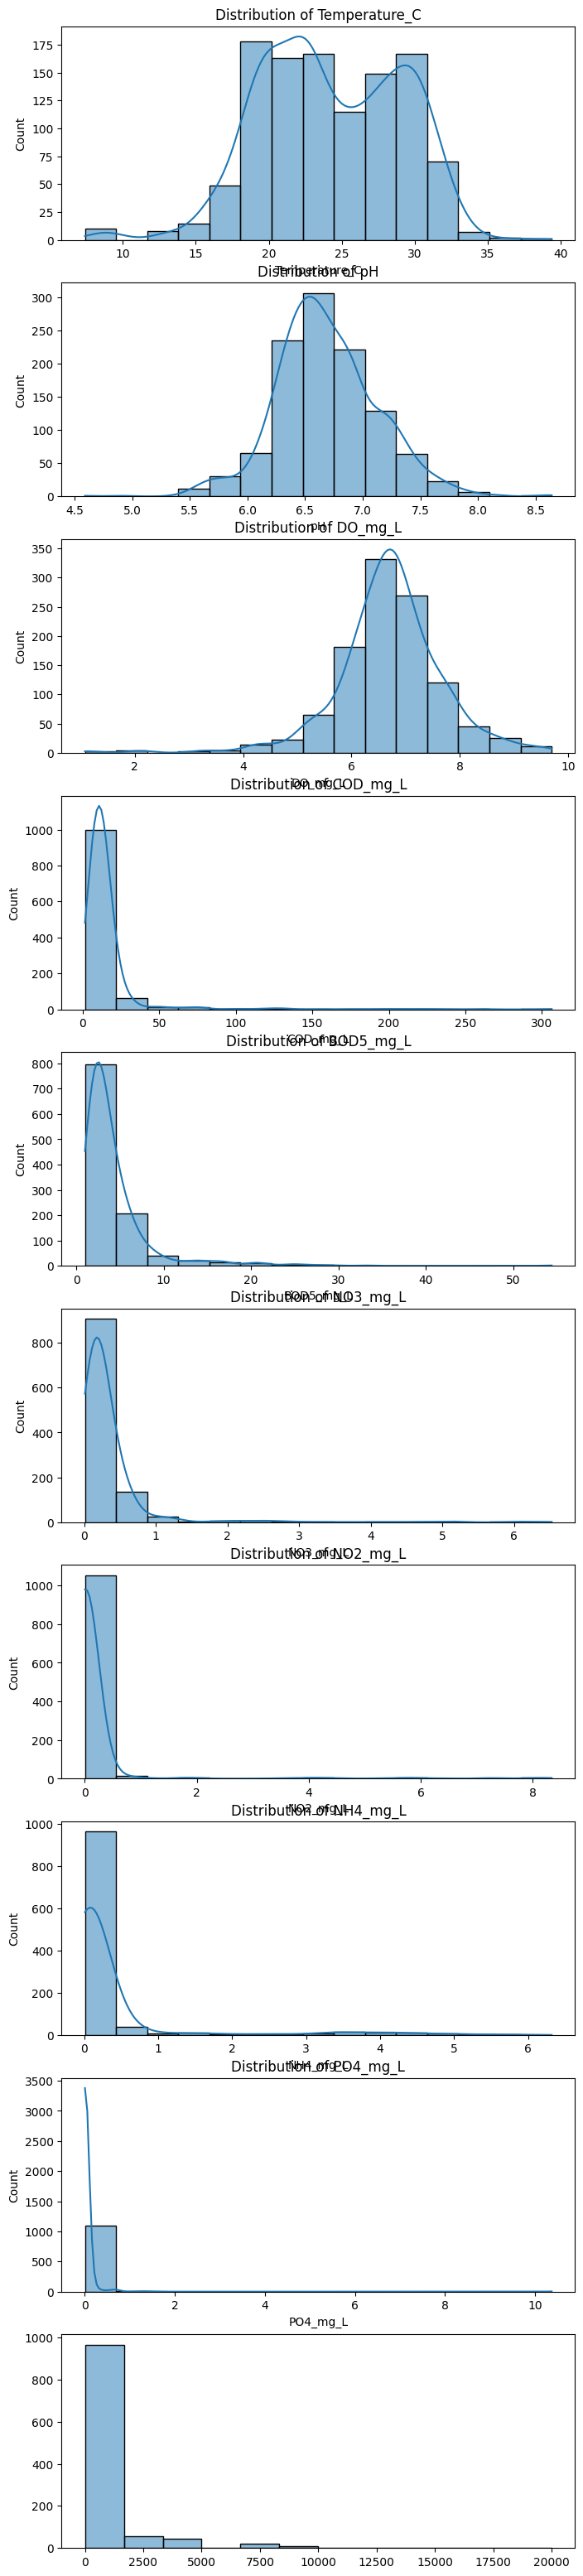

In [135]:
numeric_cols = final_data.select_dtypes(include=['int64', 'float64']).columns
n_rows = len(numeric_cols)

plt.figure(figsize=(8, 4 * n_rows))

for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows, 1, i + 1)
    sns.histplot(
        final_data[col],
        bins=15,
        kde=True
    )
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

The histogram distributions reveal important characteristics of each water quality parameter in the dataset. Each subplot shows the frequency distribution with a kernel density estimate (KDE) curve to illustrate the underlying probability distribution.

### Temperature (Temperature_C)

**Chart Components:**
- **X-axis**: Temperature values in degrees Celsius (°C)
- **Y-axis**: Frequency count of observations
- **Blue bars**: Histogram showing data distribution
- **Orange curve**: Kernel Density Estimate (KDE) showing probability distribution

**Analysis:**

The temperature distribution shows a relatively concentrated pattern with most observations falling within a narrow range around 27-29°C, indicating generally warm water conditions typical of tropical/subtropical climates. The distribution appears slightly right-skewed with a prominent peak around 28°C. A few observations at the lower end (around 20-22°C) may represent seasonal variations or samples collected during cooler periods. The narrow interquartile range suggests stable thermal conditions across most monitoring stations and time periods, which is consistent with the stable climate in Quang Ninh Province.

### pH

**Chart Components:**
- **X-axis**: pH values (dimensionless)
- **Y-axis**: Frequency count of observations

**Analysis:**

The pH distribution exhibits a relatively narrow and near-normal distribution centered around 6.5-7.5, indicating predominantly neutral to slightly acidic water conditions suitable for aquatic ecosystems. The distribution shows a clear peak around pH 7.0, suggesting most water bodies maintain near-neutral conditions. The concentration of values within this range reflects relatively stable chemical conditions across the study area. A few observations at the lower end (pH < 6) and upper end (pH > 8) may indicate localized variations due to industrial discharge, agricultural runoff, or natural geological influences. Overall, the distribution suggests good buffering capacity in the water bodies.

### Dissolved Oxygen (DO_mg_L)

**Chart Components:**
- **X-axis**: DO concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The DO distribution shows moderate variability with a concentration of values between 4-7 mg/L. The distribution appears slightly left-skewed with a peak around 5-6 mg/L, indicating generally adequate oxygen levels to support aquatic life in most samples. However, the presence of lower values (< 4 mg/L) suggests potential oxygen depletion in some locations, possibly due to organic pollution, high biological oxygen demand, or eutrophication. The wider spread compared to pH and temperature indicates greater spatial and temporal variability in oxygen availability, which may be influenced by factors such as water flow rates, temperature variations, photosynthetic activity, and organic matter decomposition.

### Chemical Oxygen Demand (COD_mg_L)

**Chart Components:**
- **X-axis**: COD concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The COD distribution shows a strongly right-skewed pattern with most observations concentrated at lower values (< 20 mg/L), indicating acceptable baseline organic content in the majority of samples. However, the long tail extending toward higher values (> 60 mg/L) reveals the presence of significant organic pollution at specific locations or time periods. This bimodal-like pattern suggests two distinct water quality regimes: one representing relatively clean water bodies and another affected by organic contamination from industrial discharge, sewage, or agricultural runoff. The extreme values warrant further investigation to identify pollution sources and implement appropriate remediation measures.

### Biochemical Oxygen Demand (BOD5_mg_L)

**Chart Components:**
- **X-axis**: BOD₅ concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The BOD₅ distribution exhibits a strong right-skew with most values clustered below 10 mg/L, indicating low levels of biodegradable organic matter in most samples. The peak near 2-4 mg/L suggests that baseline BOD₅ levels are generally within acceptable ranges for surface water quality. However, several outliers extending to 30+ mg/L indicate episodic or localized organic pollution events, likely from domestic wastewater, agricultural activities, or industrial sources. The presence of these elevated values suggests potential stress on aquatic ecosystems due to increased oxygen consumption during organic matter decomposition, which could lead to oxygen depletion if not properly managed.

### Nitrate (NO3_mg_L)

**Chart Components:**
- **X-axis**: NO₃⁻ concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The nitrate distribution shows a right-skewed pattern with most observations concentrated near zero and a long tail extending to higher values. The majority of samples exhibit low nitrate concentrations (< 5 mg/L), suggesting limited nutrient loading under typical conditions. However, the presence of outliers reaching 15-20 mg/L indicates occasional nutrient enrichment events, likely associated with agricultural runoff from fertilizer application, livestock operations, or inadequately treated wastewater. These elevated concentrations pose a risk of eutrophication, particularly in sensitive water bodies such as lakes and coastal areas. The overall pattern suggests that while baseline nitrate levels are generally acceptable, targeted management interventions may be needed in specific locations or during high-input periods.

### Nitrite (NO2_mg_L)

**Chart Components:**
- **X-axis**: NO₂⁻ concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The nitrite distribution is extremely right-skewed, with the vast majority of values clustered very close to zero (< 0.05 mg/L), indicating minimal nitrite presence in most water samples. This pattern reflects efficient nitrogen cycling processes and stable nitrification-denitrification dynamics in most locations. The extremely narrow concentration range around zero suggests that nitrite, an intermediate product in nitrogen transformation, does not accumulate under normal conditions. However, a few distinct outliers at higher concentrations (> 0.3 mg/L) may indicate incomplete nitrification processes, possibly due to oxygen limitation, pH imbalances, or inhibition of nitrifying bacteria. Although infrequent, these elevated nitrite levels warrant attention due to potential toxicity to aquatic organisms.

### Ammonium (NH4_mg_L)

**Chart Components:**
- **X-axis**: NH₄⁺ concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The ammonium distribution displays a strong right-skew with most values concentrated below 2 mg/L, indicating minimal ammonia pollution in the majority of samples. The peak near 0.5-1.0 mg/L suggests that baseline ammonium levels are generally low and stable across most monitoring locations. However, the presence of numerous outliers extending to 10+ mg/L indicates episodic ammonia inputs from sources such as untreated wastewater discharge, livestock operations, aquaculture activities, or organic matter decomposition. These elevated concentrations are concerning because ammonia is toxic to aquatic life, particularly in its unionized form (NH₃), which increases with pH and temperature. The distribution pattern suggests that while general water quality is acceptable, localized pollution hotspots require targeted intervention.

### Phosphate (PO4_mg_L)

**Chart Components:**
- **X-axis**: PO₄³⁻ concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The phosphate distribution is highly right-skewed with the vast majority of observations concentrated very close to zero (< 0.2 mg/L), indicating minimal phosphorus enrichment in most samples. This pattern suggests limited anthropogenic phosphorus inputs under typical conditions, which is favorable for preventing eutrophication. The extremely narrow concentration range reflects effective phosphorus retention in soils and sediments or limited phosphorus sources in the catchment. However, several distinct outliers at higher concentrations (> 0.5 mg/L) indicate sporadic phosphate inputs, potentially from fertilizer runoff, detergents in domestic wastewater, or industrial sources. Although these spikes are infrequent, they merit attention because phosphorus is often the limiting nutrient for algal growth in freshwater systems.

### Coliform (Coliform_MPN_100ml)

**Chart Components:**
- **X-axis**: Coliform count in MPN/100mL
- **Y-axis**: Frequency count of observations

**Analysis:**

The Coliform distribution exhibits an extreme right-skew with a highly concentrated peak near zero and a very long tail extending to extremely high values (> 20,000 MPN/100mL). Most samples show relatively low coliform counts (< 5,000 MPN/100mL), suggesting that baseline microbiological conditions are moderately controlled. However, numerous high outliers indicate severe fecal contamination events at specific locations or time periods, likely from untreated sewage discharge, surface runoff carrying animal waste, or inadequate sanitation infrastructure. The wide range of values reflects significant spatial and temporal variability in microbiological water quality, with some areas experiencing chronic or acute contamination that poses serious public health risks. This pattern necessitates targeted microbiological monitoring and remediation efforts, particularly near population centers and recreational water use areas.

### E. coli (EColi)

**Chart Components:**
- **X-axis**: E. coli count in MPN/100mL
- **Y-axis**: Frequency count of observations

**Analysis:**

The E. coli distribution mirrors the Coliform pattern with an extreme right-skew and most values concentrated near zero or low levels (< 100 MPN/100mL). This indicates that the majority of samples are relatively free from recent fecal contamination, suggesting acceptable baseline conditions in many locations. However, the presence of multiple high outliers (> 500 MPN/100mL) reveals episodic or localized fecal pollution events, likely from the same sources affecting total coliform counts: sewage discharge, agricultural runoff, or wildlife waste. As E. coli is a more specific indicator of fecal contamination than total coliforms, these elevated values are particularly concerning for public health. The distribution pattern emphasizes the need for regular microbiological monitoring, source tracking, and implementation of water quality management measures to protect human health and ecosystem integrity.

### Arsenic (As_mg_L)

**Chart Components:**
- **X-axis**: Arsenic concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The arsenic distribution is highly right-skewed with most values clustered extremely close to zero (< 0.01 mg/L), indicating minimal arsenic contamination in the majority of water samples. This pattern reflects low baseline arsenic levels, which may be attributed to limited geological sources or effective natural attenuation processes. The extremely narrow interquartile range suggests stable arsenic concentrations across most monitoring locations. However, several distinct outliers at higher concentrations (0.02-0.05 mg/L) indicate occasional exceedances, potentially linked to natural geological formations rich in arsenic-bearing minerals or anthropogenic sources such as mining activities, industrial processes, or agricultural chemicals. Although typical arsenic levels are reassuringly low, these outliers warrant careful attention due to arsenic's high toxicity and carcinogenic properties, even at relatively low chronic exposure levels.

### Mercury (Hg_mg_L)

**Chart Components:**
- **X-axis**: Mercury concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The mercury distribution exhibits an extreme right-skew with the overwhelming majority of values tightly clustered at or near zero (< 0.001 mg/L), indicating generally low background mercury levels across the study area. The extremely narrow central distribution suggests minimal mercury presence under typical environmental conditions, which is favorable given mercury's extreme toxicity. However, several pronounced outliers at significantly higher concentrations (> 0.005 mg/L) reveal sporadic mercury contamination events. These outliers may be associated with localized pollution sources such as industrial facilities, artisanal gold mining, fossil fuel combustion, or accidental spills. Despite the low median concentration, these extreme values are environmentally critical because mercury bioaccumulates in aquatic food chains and causes severe neurological damage even at very low concentrations. The presence of any detectable mercury levels necessitates continued vigilant monitoring and source identification.

### Lead (Pb_mg_L)

**Chart Components:**
- **X-axis**: Lead concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The lead distribution shows a wider spread compared to mercury and arsenic, with a right-skewed pattern but less extreme concentration at zero. Most observations fall below 0.03 mg/L, suggesting generally low but detectable lead levels in many samples. The distribution indicates that lead is present at measurable concentrations more frequently than mercury or arsenic, possibly due to more diverse and widespread sources. Numerous outliers extending to 0.08+ mg/L reveal considerable variability in lead contamination across sampling locations and time periods. The frequent occurrence of elevated values suggests that lead pollution is not isolated but influenced by multiple anthropogenic sources such as industrial effluents, leaded gasoline residues, battery manufacturing, mining activities, or deteriorating lead-based infrastructure. This distribution pattern highlights lead as a critical parameter requiring close monitoring and source control measures.

### Cadmium (Cd_mg_L)

**Chart Components:**
- **X-axis**: Cadmium concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The cadmium distribution closely resembles the mercury pattern, with most values tightly concentrated near zero (< 0.005 mg/L), indicating minimal cadmium presence in the majority of water samples. The extremely narrow central distribution reflects low baseline cadmium levels across most monitoring locations. However, several pronounced outliers at significantly higher concentrations (> 0.01 mg/L) indicate occasional contamination spikes. These outliers may reflect localized pollution from industrial sources such as electroplating, battery manufacturing, pigment production, or metal smelting operations. Given cadmium's high toxicity, carcinogenicity, and tendency to bioaccumulate in kidneys and other organs, even these infrequent spikes are of significant environmental and public health concern. The distribution emphasizes the need for targeted source identification and control measures at locations showing elevated cadmium levels.

### Hexavalent Chromium (CrVI)

**Chart Components:**
- **X-axis**: Cr(VI) concentration in mg/L
- **Y-axis**: Frequency count of observations

**Analysis:**

The hexavalent chromium distribution exhibits a strong right-skew similar to other heavy metals, with most values clustered near zero (< 0.01 mg/L), indicating generally low background Cr(VI) levels. The narrow concentration range for the majority of samples suggests limited chromium contamination under typical conditions. However, several distinct outliers at markedly higher concentrations (> 0.03 mg/L) indicate sporadic but significant chromium contamination events. These outliers may be linked to specific industrial activities such as electroplating, leather tanning, textile dyeing, or stainless steel manufacturing. The presence of hexavalent chromium is particularly concerning because Cr(VI) is highly toxic, mobile in aquatic environments, and classified as a human carcinogen. Unlike trivalent chromium (Cr(III)), which is relatively benign, Cr(VI) poses severe health and environmental risks even at low concentrations, warranting careful monitoring and targeted management at affected locations.

### Water Quality Index (VN_WQI)

**Chart Components:**
- **X-axis**: VN_WQI score (0-100 scale)
- **Y-axis**: Frequency count of observations

**Analysis:**

The VN_WQI distribution shows a relatively wide spread with most values concentrated between 40-80, indicating variable water quality across the study area. The distribution appears slightly left-skewed with a peak around 60-70, suggesting that many water bodies fall within the "fair" to "good" quality categories according to Vietnamese standards. The presence of values across the entire spectrum from "very poor" (< 25) to "excellent" (> 91) reflects significant heterogeneity in environmental conditions, pollution pressures, and water management practices across different monitoring locations. The relatively normal distribution pattern suggests that the calculated WQI effectively captures the overall variability in water quality parameters and provides a meaningful integrated assessment. Areas with lower WQI scores (< 50) require priority attention for pollution control and remediation efforts.

---

**Overall Conclusions:**

1. **General Pattern**: Most parameters show right-skewed distributions with low median values but occasional high outliers, indicating generally acceptable baseline conditions punctuated by localized or episodic pollution events.

2. **Pollution Indicators**: The presence of extreme outliers in nutrients (NO₃⁻, NH₄⁺, PO₄³⁻), organic matter (COD, BOD₅), microbiological indicators (Coliform, E. coli), and heavy metals suggests that while overall water quality is moderately good, specific locations or time periods experience significant contamination.

3. **Priority Parameters**: Heavy metals (Pb, Hg, Cd, Cr(VI)) and microbiological indicators (Coliform, E. coli) show the most concerning outlier patterns and should be prioritized for targeted monitoring and source control.

4. **Spatial Heterogeneity**: The wide variability in most parameters indicates significant spatial heterogeneity in water quality across Quang Ninh Province, likely reflecting diverse land uses, pollution sources, and environmental conditions.

5. **Management Implications**: The distribution patterns suggest that effective water quality management should focus on identifying and controlling pollution hotspots while maintaining baseline conditions in less-impacted areas.

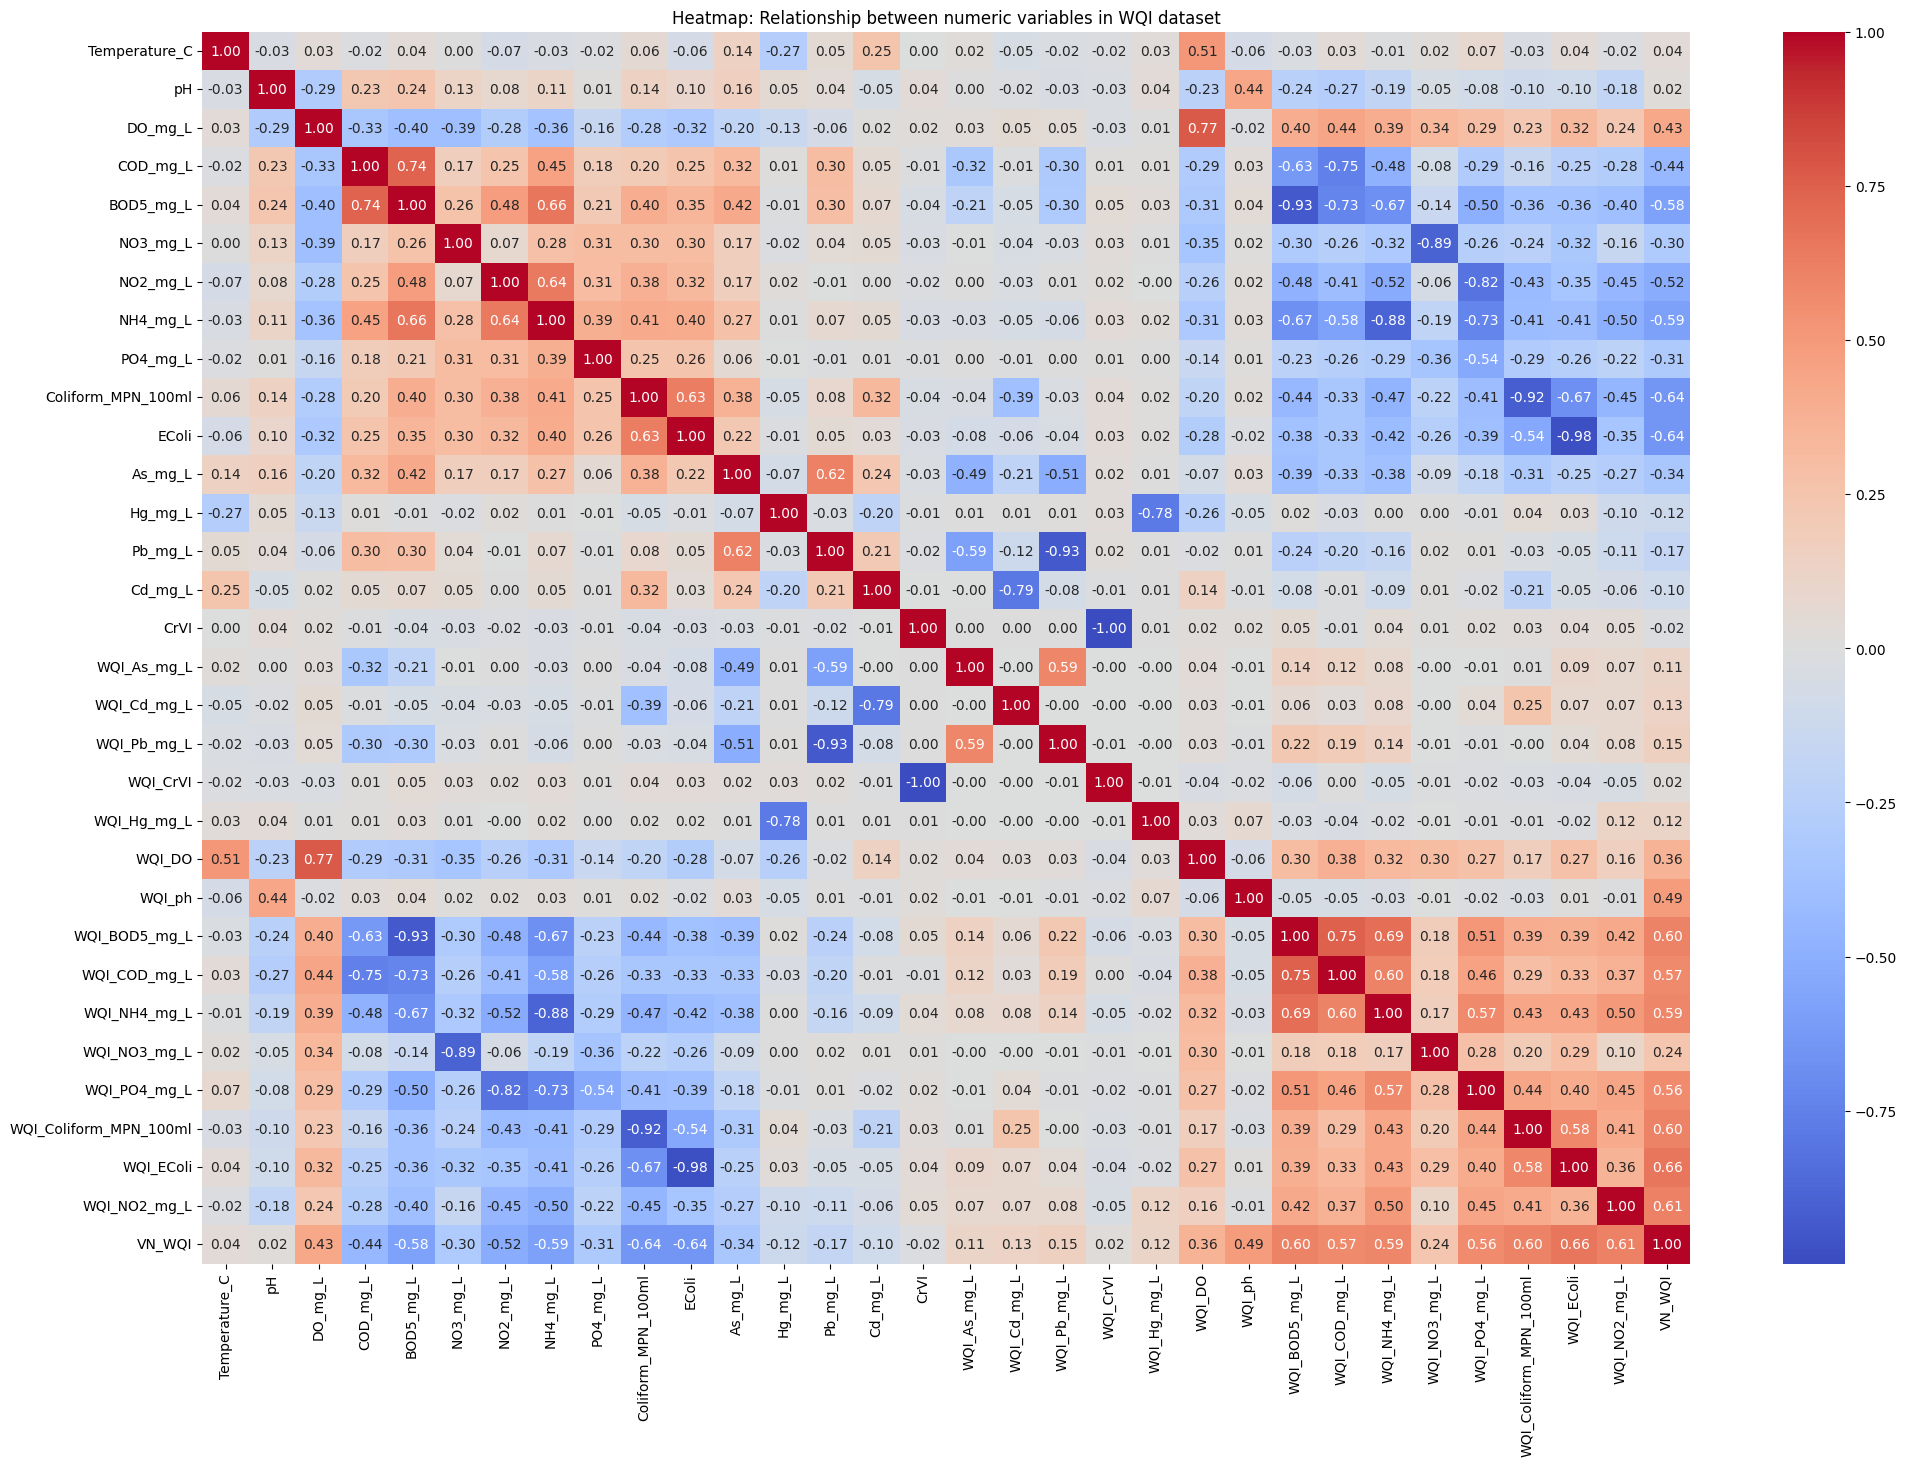

In [ ]:
# Get numeric columns
numeric_cols = final_data.select_dtypes(include=['int64', 'float64']).columns
df_numeric = final_data[numeric_cols]

# Calculate correlation matrix
corr_matrix = df_numeric.corr()

plt.figure(figsize=(24, 16))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Heatmap: Relationship between numeric variables in WQI dataset")
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_7408\229870674.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


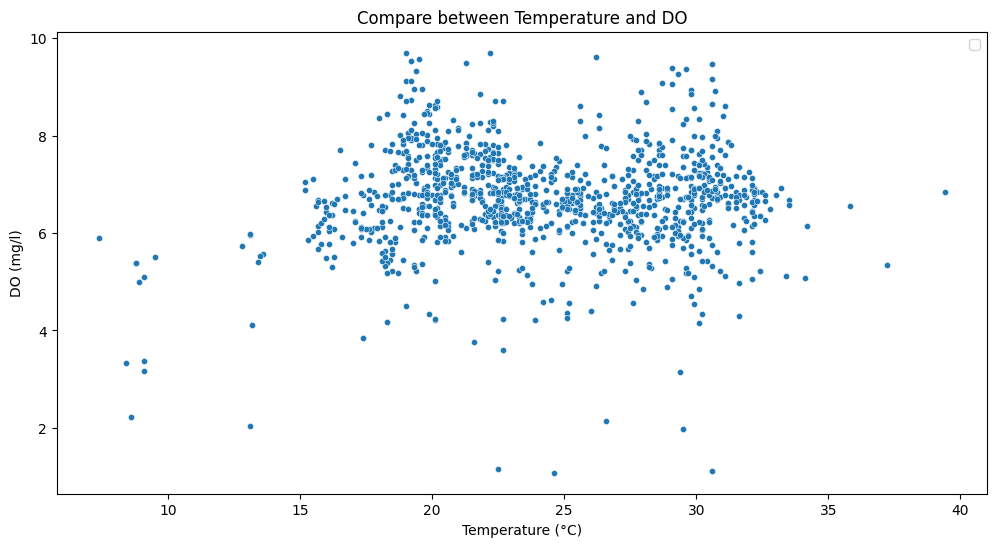

In [ ]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=final_data, x='Temperature_C', y='DO_mg_L',s=20)
plt.title('Compare between Temperature and DO')
plt.xlabel('Temperature (°C)')
plt.ylabel('DO (mg/l)')
plt.legend()
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_7408\2168312862.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


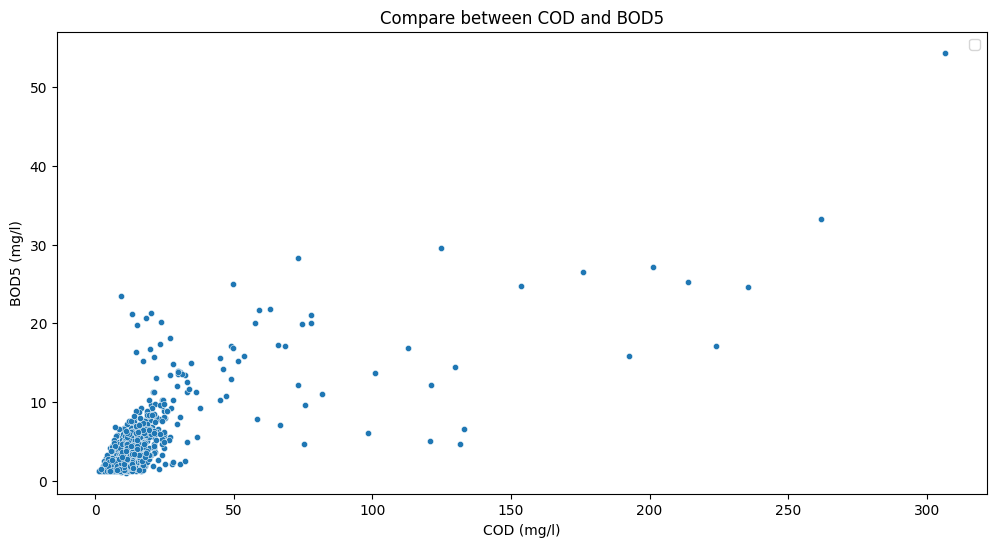

In [ ]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=final_data, x='COD_mg_L', y='BOD5_mg_L',s=20)
plt.title('Compare between COD and BOD5')
plt.xlabel('COD (mg/l)')
plt.ylabel('BOD5 (mg/l)')
plt.legend()
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_7408\2955410386.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


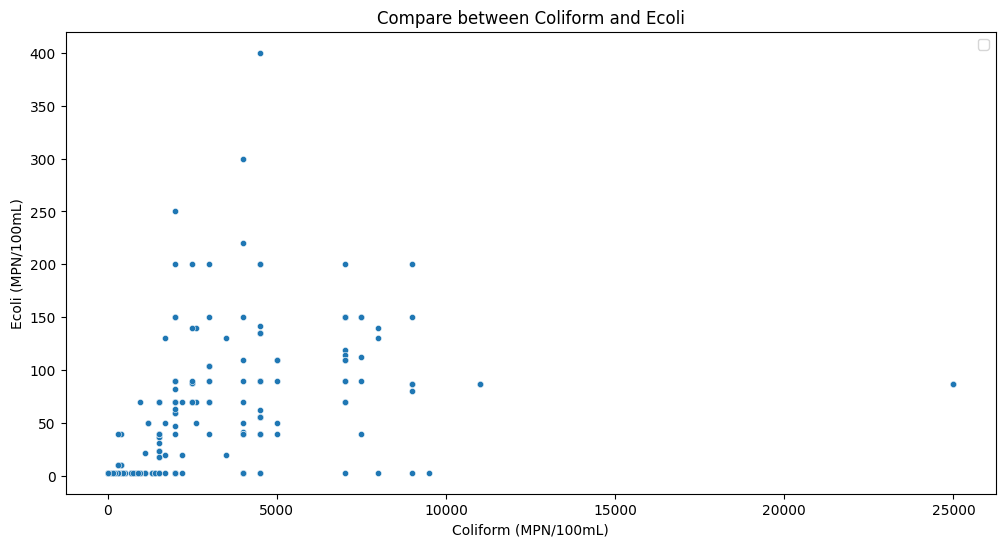

In [ ]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=final_data, x='Coliform_MPN_100ml', y='EColi',s=20)
plt.title('Compare between Coliform and Ecoli')
plt.xlabel('Coliform (MPN/100mL)')
plt.ylabel('Ecoli (MPN/100mL)')
plt.legend()
plt.show()

# 3. Feature Engineering


---

In [ ]:
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LinearRegression())
])

knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor())
])

svr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

Standard scaling is applied for Linear Regression and K-Nearest Neighbors because these models are sensitive to the scale of features. On the other hand, Random Forest and Gradient Boosting do not require feature scaling, as they are tree-based models and are insensitive to the magnitude of the features.

# 4. Classifier Training


---

## 4.1. Data Splitting

In [ ]:
final_data.shape

(1101, 32)

In [ ]:
# Separate X and y
X = final_data[['WQI_ph', 'WQI_DO', 'WQI_COD_mg_L', 'WQI_BOD5_mg_L', 
                'WQI_NO3_mg_L', 'WQI_NO2_mg_L', 'WQI_NH4_mg_L', 'WQI_PO4_mg_L', 
                'WQI_Coliform_MPN_100ml', 'WQI_EColi', 'WQI_As_mg_L', 'WQI_Hg_mg_L', 'WQI_Pb_mg_L', 
                'WQI_Cd_mg_L', 'WQI_CrVI']]  # Features
y = final_data['VN_WQI']  # WQI index

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 4.2. Model Training

In [ ]:
# Define the parameter grid for RandomForest
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 20, 40],
    'min_samples_leaf': [1, 2, 5],
    'max_features': ['sqrt', 0.7, 1.0]
}


# Initialize GridSearchCV for RandomForest
rf_grid_search = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=5, n_jobs=-1)
rf_grid_search.fit(X, y)

# Get the best hyperparameters from GridSearchCV
best_rf_params = rf_grid_search.best_params_
print("Best parameters for RandomForest:", best_rf_params)

KeyboardInterrupt: 

In [ ]:
# Define the parameter grid for GradientBoosting
gb_param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

# Initialize GridSearchCV for GradientBoosting
gb_grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_param_grid, cv=5, n_jobs=-1)
gb_grid_search.fit(X, y)

# Get the best hyperparameters from GridSearchCV
best_gb_params = gb_grid_search.best_params_
print("Best parameters for GradientBoosting:", best_gb_params)

Best parameters for GradientBoosting: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}


In [ ]:
# Define the parameter grid for KNN
knn_param_grid = {
    'knn__n_neighbors': [3, 5, 6, 7, 9],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['minkowski', 'euclidean', 'manhattan'],
    'knn__p': [1, 2]
}

# Initialize GridSearchCV for KNN
knn_grid_search = GridSearchCV(
    estimator=knn_model,
    param_grid=knn_param_grid,
    cv=5,             
    n_jobs=-1
)
knn_grid_search.fit(X, y)

# Get the best hyperparameters from GridSearchCV
best_knn_params = knn_grid_search.best_params_
print("Best parameters:", knn_grid_search.best_params_)

Best parameters: {'knn__metric': 'minkowski', 'knn__n_neighbors': 3, 'knn__p': 2, 'knn__weights': 'distance'}


In [ ]:
# Define the parameter grid for SVR
param_grid = {
    'svr__C': [0.1, 1, 10, 100],
    'svr__epsilon': [0.01, 0.1, 0.2, 0.5],
    'svr__gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

# GridSearchCV
svr_grid_search = GridSearchCV(
    estimator=svr_model,
    param_grid=param_grid,
    cv=5,
    n_jobs=-1
)
svr_grid_search.fit(X, y)
# Get the best hyperparameters from GridSearchCV
best_svr_params = svr_grid_search.best_params_
print("Best parameters for SVR:", best_svr_params)

Best parameters for SVR: {'svr__C': 100, 'svr__epsilon': 0.5, 'svr__gamma': 0.01}


In [ ]:
# Random Forest model
rf_model = RandomForestRegressor(**best_rf_params, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Gradient Boosting model
gb_model = GradientBoostingRegressor(**best_gb_params, random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

# Linear Regression model
lr_model = BaggingRegressor(estimator=lr_model, n_estimators=200, random_state=42)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# KNN model
knn_model = knn_model.set_params(**{'knn__n_neighbors': best_knn_params['knn__n_neighbors'],
                                 'knn__weights': best_knn_params['knn__weights'],
                                 'knn__metric': best_knn_params['knn__metric'],
                                 'knn__p': best_knn_params['knn__p']})
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

# SVR model
svr_model = svr_model.set_params(**{'svr__C': best_svr_params['svr__C'],
                                 'svr__epsilon': best_svr_params['svr__epsilon'],
                                 'svr__gamma': best_svr_params['svr__gamma']})
svr_model = BaggingRegressor(estimator=svr_model, n_estimators=200, random_state=42)
svr_model.fit(X_train, y_train)
svr_pred = svr_model.predict(X_test)

In [ ]:
print("Random Forest - MSE:", mean_squared_error(y_test, rf_pred))
print("Random Forest - RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("Random Forest - MAE:", mean_absolute_error(y_test, rf_pred))
print("Random Forest - R^2:", r2_score(y_test, rf_pred))

print("\n" + "="*50 + "\n")

print("Gradient Boosting - MSE:", mean_squared_error(y_test, gb_pred))
print("Gradient Boosting - RMSE:", np.sqrt(mean_squared_error(y_test, gb_pred)))
print("Gradient Boosting - MAE:", mean_absolute_error(y_test, gb_pred))
print("Gradient Boosting - R^2:", r2_score(y_test, gb_pred))

print("\n" + "="*50 + "\n")

print("Linear Regression - MSE:", mean_squared_error(y_test, lr_pred))
print("Linear Regression - RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("Linear Regression - MAE:", mean_absolute_error(y_test, lr_pred))
print("Linear Regression - R^2:", r2_score(y_test, lr_pred))

print("\n" + "="*50 + "\n")

print("K-Nearest Neighbors - MSE:", mean_squared_error(y_test, knn_pred))
print("K-Nearest Neighbors - RMSE:", np.sqrt(mean_squared_error(y_test, knn_pred)))
print("K-Nearest Neighbors - MAE:", mean_absolute_error(y_test, knn_pred))
print("K-Nearest Neighbors - R^2:", r2_score(y_test, knn_pred))

print("\n" + "="*50 + "\n")

print("Support Vector Regression - MSE:", mean_squared_error(y_test, svr_pred))
print("Support Vector Regression - RMSE:", np.sqrt(mean_squared_error(y_test, svr_pred)))
print("Support Vector Regression - MAE:", mean_absolute_error(y_test, svr_pred))
print("Support Vector Regression - R^2:", r2_score(y_test, svr_pred))

Random Forest - MSE: 3.535764705882354
Random Forest - RMSE: 1.8803629186628719
Random Forest - MAE: 0.7122171945701359
Random Forest - R^2: 0.9698508933681153


Gradient Boosting - MSE: 3.429219695905239
Gradient Boosting - RMSE: 1.8518152434584934
Gradient Boosting - MAE: 0.7538452619312106
Gradient Boosting - R^2: 0.9707593918498019


Linear Regression - MSE: 0.7499717542592929
Linear Regression - RMSE: 0.8660090959448942
Linear Regression - MAE: 0.45032980178168847
Linear Regression - R^2: 0.993605067002211


K-Nearest Neighbors - MSE: 2.841422900437484
K-Nearest Neighbors - RMSE: 1.6856520698048822
K-Nearest Neighbors - MAE: 0.7023781876878568
K-Nearest Neighbors - R^2: 0.9757714754409285


Support Vector Regression - MSE: 0.7262659547171113
Support Vector Regression - RMSE: 0.8522123882678022
Support Vector Regression - MAE: 0.4017366387820552
Support Vector Regression - R^2: 0.9938072039478629


- Tree-based ensemble models (Random Forest and Gradient Boosting) clearly outperform other models in terms of all evaluated metrics. Gradient Boosting achieves the lowest MSE and MAE, as well as the highest R² value, indicating superior predictive accuracy and robustness.

- Support Vector Regression (SVR) shows competitive performance, particularly with respect to MAE and R², suggesting that it is able to capture the underlying relationships in the data more effectively than simpler models.

- K-Nearest Neighbors (KNN) provides moderate predictive performance. While its RMSE and R² are acceptable, it is less accurate than ensemble methods, which may be due to its sensitivity to feature scaling and local data structure.

- Linear Regression performs the poorest among all evaluated models, reflected by substantially higher MSE and RMSE values and a lower R². This suggests that the relationships in the dataset are likely non-linear, which linear regression fails to fully capture.

Overall Observations:

Ensemble tree-based models are highly effective for this dataset, likely due to their ability to handle complex, non-linear interactions among features.

Simpler models such as linear regression and KNN may be useful for preliminary analysis or interpretation but are insufficient for high-accuracy predictions.

Model selection should balance predictive performance with interpretability and computational efficiency depending on the application.

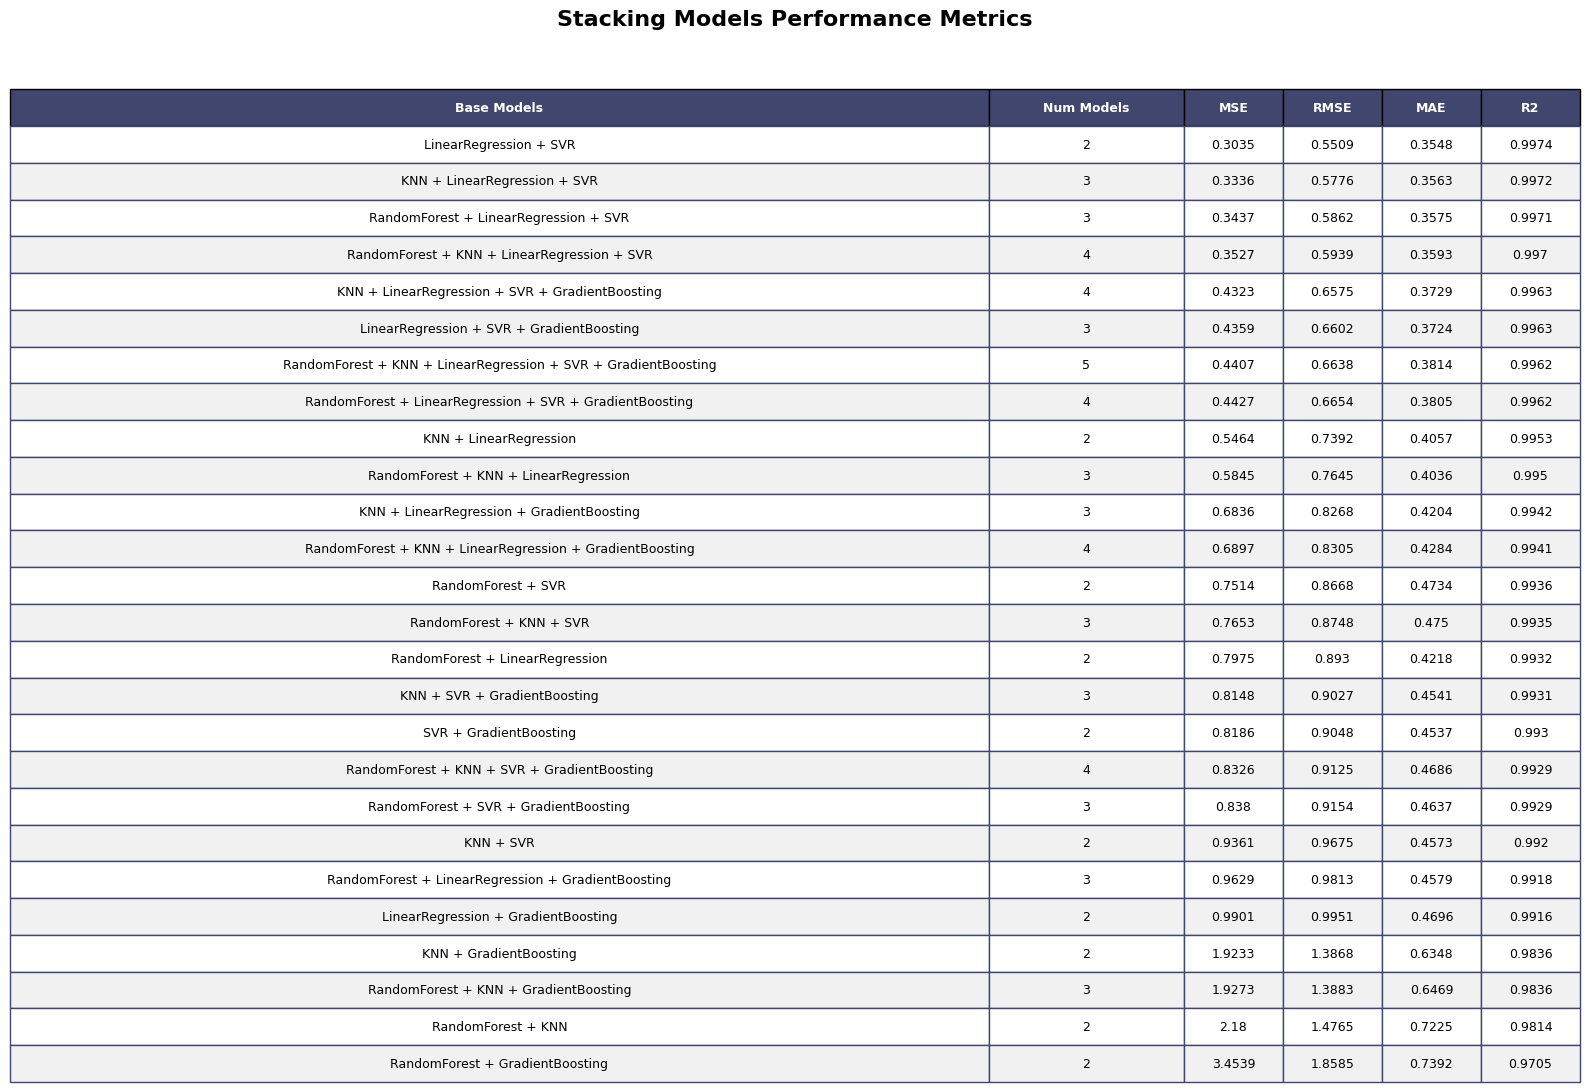

In [ ]:
optimized_models = {
    'RandomForest': rf_model,
    'KNN': knn_model,
    'LinearRegression': lr_model,
    'SVR': svr_model,
    'GradientBoosting': gb_model
}

meta_model = LinearRegression()
results = []
model_names = list(optimized_models.keys())

for r in range(2, len(model_names) + 1):
    for combo in itertools.combinations(model_names, r):
        estimators = [(name.lower(), optimized_models[name]) for name in combo]

        stacking = StackingRegressor(
            estimators=estimators,
            final_estimator=meta_model,
            n_jobs=-1
        )

        stacking.fit(X_train, y_train)
        preds = stacking.predict(X_test)

        mse = mean_squared_error(y_test, preds)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_test, preds)
        r2 = r2_score(y_test, preds)

        results.append({
            'Base Models': " + ".join(combo),
            'Num Models': len(combo),
            'MSE': mse,
            'RMSE': rmse,
            'MAE': mae,
            'R2': r2
        })

results_df = pd.DataFrame(results).sort_values(by='RMSE')

fig, ax = plt.subplots(figsize=(16, len(results_df) * 0.35 + 2))
ax.axis('off')

tbl = ax.table(
    cellText=results_df.round(4).values,
    colLabels=results_df.columns,
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 0.95]
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.auto_set_column_width(col=list(range(len(results_df.columns))))

for (i, j), cell in tbl.get_celld().items():
    cell.set_height(0.06)
    if i == 0:
        cell.set_facecolor('#40466e')
        cell.set_text_props(weight='bold', color='w')
    else:
        cell.set_facecolor('#f1f1f2' if i % 2 == 0 else 'white')
        cell.set_edgecolor('#40466e')

fig.suptitle("Stacking Models Performance Metrics", fontsize=16, weight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [ ]:
# Optimized base models
optimized_models = {
    'RandomForest': rf_model,
    'KNN': knn_model,
    'LinearRegression': lr_model,
    'SVR': svr_model,
    'GradientBoosting': gb_model
}

# Meta-model - this is the model for learning the ensemble
meta_model = LinearRegression()

# Create the StackingRegressor with base models and the meta-model
stacking_model = StackingRegressor(
    estimators=[('svr', optimized_models['SVR']),
                ('lr', optimized_models['LinearRegression']),
                ('gb', optimized_models['GradientBoosting'])],
    final_estimator=meta_model
)

# Train the stacking model on the training data (X_train and y_train)
stacking_model.fit(X_train, y_train)
sm_pred = stacking_model.predict(X_test)

In [ ]:
print("Stacking Model - MSE:", mean_squared_error(y_test, sm_pred))
print("Stacking Model - RMSE:", np.sqrt(mean_squared_error(y_test, sm_pred)))
print("Stacking Model - MAE:", mean_absolute_error(y_test, sm_pred))
print("Stacking Model - R^2:", r2_score(y_test, sm_pred))

Stacking Model - MSE: 0.43590395108936064
Stacking Model - RMSE: 0.6602302258222965
Stacking Model - MAE: 0.3724418936284291
Stacking Model - R^2: 0.9962830912699624


# 5. Feature Importance


---

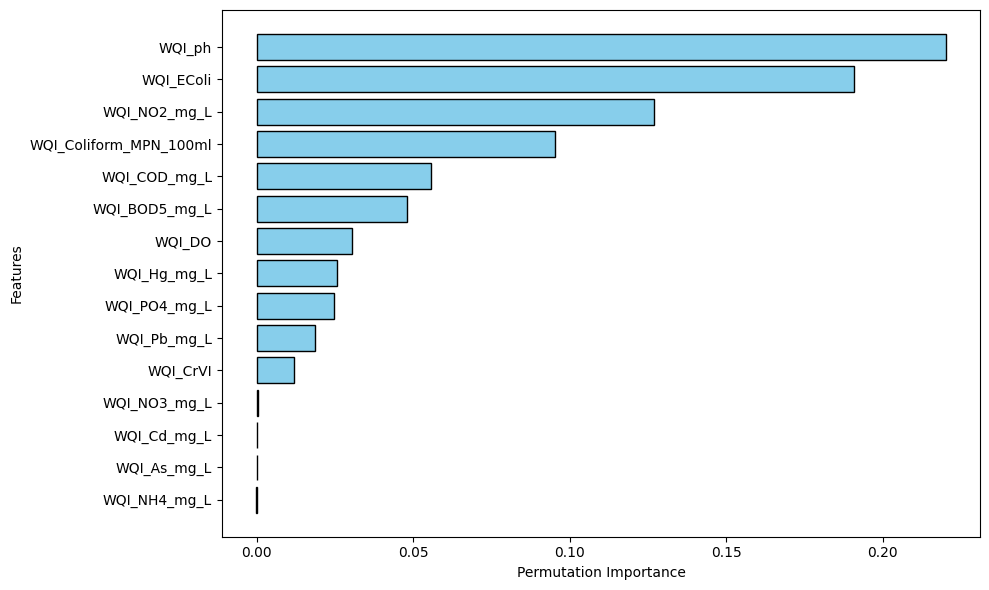

In [ ]:
# Calculate Permutation Importance
perm_importance = permutation_importance(stacking_model, X_test, y_test, n_repeats=30, random_state=42)

# Get the mean values and sort features by importance
sorted_idx = perm_importance.importances_mean.argsort()

# Plot the bar chart
plt.figure(figsize=(10, 6))
plt.barh(
    X_test.columns[sorted_idx], 
    perm_importance.importances_mean[sorted_idx], 
    color="skyblue", 
    edgecolor="black"
)
plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# 6. Retrain after remove unimportant features


---

## 6.1 Data Splitting


---

In [ ]:
# Separate X and y
X_retrain = final_data[['WQI_ph', 'WQI_DO', 'WQI_COD_mg_L', 
                'WQI_NO2_mg_L', 'WQI_PO4_mg_L', 
                'WQI_EColi', 'WQI_Hg_mg_L', 'WQI_Pb_mg_L', 
                'WQI_CrVI']]
y_retrain = final_data['VN_WQI']  # WQI index

# Split data
X_train_retrain, X_test_retrain, y_train_retrain, y_test_retrain = train_test_split(X_retrain, y_retrain, test_size=0.2, random_state=42)

## 6.2 Model Training


---

In [ ]:
# Define the parameter grid for RandomForest
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 20, 40],
    'min_samples_leaf': [1, 2, 5],
    'max_features': ['sqrt', 0.7, 1.0]
}

# Initialize GridSearchCV for RandomForest
rf_grid_search_retrain = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=5, n_jobs=-1)
rf_grid_search_retrain.fit(X_retrain, y_retrain)

# Get the best hyperparameters from GridSearchCV
best_rf_params_retrain = rf_grid_search_retrain.best_params_
print("Best parameters for RandomForest:", best_rf_params_retrain)

In [ ]:
# Define the parameter grid for GradientBoosting
gb_param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

# Initialize GridSearchCV for GradientBoosting
gb_grid_search_retrain = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_param_grid, cv=5, n_jobs=-1)
gb_grid_search_retrain.fit(X_retrain, y_retrain)

# Get the best hyperparameters from GridSearchCV
best_gb_params_retrain = gb_grid_search_retrain.best_params_
print("Best parameters for GradientBoosting:", best_gb_params_retrain)

In [ ]:
# Define the parameter grid for KNN
knn_param_grid = {
    'knn__n_neighbors': [3, 5, 6, 7, 9],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['minkowski', 'euclidean', 'manhattan'],
    'knn__p': [1, 2]
}

# Initialize GridSearchCV for KNN
knn_grid_search_retrain = GridSearchCV(
    estimator=knn_model,
    param_grid=knn_param_grid,
    cv=5,             
    n_jobs=-1
)
knn_grid_search_retrain.fit(X_retrain, y_retrain)

# Get the best hyperparameters from GridSearchCV
best_knn_params_retrain = knn_grid_search_retrain.best_params_
print("Best parameters:", knn_grid_search_retrain.best_params_)

In [ ]:
# Define the parameter grid for SVR
param_grid = {
    'svr__C': [0.1, 1, 10, 100],
    'svr__epsilon': [0.01, 0.1, 0.2, 0.5],
    'svr__gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

# GridSearchCV
svr_grid_search_retrain = GridSearchCV(
    estimator=svr_model,
    param_grid=param_grid,
    cv=5,
    n_jobs=-1
)
svr_grid_search_retrain.fit(X_retrain, y_retrain)
# Get the best hyperparameters from GridSearchCV
best_svr_params_retrain = svr_grid_search_retrain.best_params_
print("Best parameters for SVR:", best_svr_params_retrain)

In [ ]:
# Random Forest model
rf_model_retrain = RandomForestRegressor(**best_rf_params_retrain, random_state=42)
rf_model_retrain.fit(X_train_retrain, y_train_retrain)
rf_pred_retrain = rf_model_retrain.predict(X_test_retrain)

# Gradient Boosting model
gb_model_retrain = GradientBoostingRegressor(**best_gb_params_retrain, random_state=42)
gb_model_retrain.fit(X_train_retrain, y_train_retrain)
gb_pred_retrain = gb_model_retrain.predict(X_test_retrain)

# Linear Regression model
lr_model_retrain = BaggingRegressor(estimator=lr_model, n_estimators=200, random_state=42)
lr_model_retrain.fit(X_train_retrain, y_train_retrain)
lr_pred_retrain = lr_model_retrain.predict(X_test_retrain)

# KNN model
knn_model_retrain = knn_model.set_params(**{'knn__n_neighbors': best_knn_params_retrain['knn__n_neighbors'],
                                 'knn__weights': best_knn_params_retrain['knn__weights'],
                                 'knn__metric': best_knn_params_retrain['knn__metric'],
                                 'knn__p': best_knn_params_retrain['knn__p']})
knn_model_retrain.fit(X_train_retrain, y_train_retrain)
knn_pred_retrain = knn_model_retrain.predict(X_test_retrain)

# SVR model
svr_model_retrain = svr_model.set_params(**{'svr__C': best_svr_params_retrain['svr__C'],
                                 'svr__epsilon': best_svr_params_retrain['svr__epsilon'],
                                 'svr__gamma': best_svr_params_retrain['svr__gamma']})
svr_model_retrain = BaggingRegressor(estimator=svr_model_retrain, n_estimators=200, random_state=42)
svr_model_retrain.fit(X_train_retrain, y_train_retrain)
svr_pred_retrain = svr_model_retrain.predict(X_test_retrain)

In [ ]:
print("Random Forest - MSE:", mean_squared_error(y_test_retrain, rf_pred_retrain))
print("Random Forest - RMSE:", np.sqrt(mean_squared_error(y_test_retrain, rf_pred_retrain)))
print("Random Forest - MAE:", mean_absolute_error(y_test_retrain, rf_pred_retrain))
print("Random Forest - R^2:", r2_score(y_test_retrain, rf_pred_retrain))

print("\n" + "="*50 + "\n")

print("Gradient Boosting - MSE:", mean_squared_error(y_test_retrain, gb_pred_retrain))
print("Gradient Boosting - RMSE:", np.sqrt(mean_squared_error(y_test_retrain, gb_pred_retrain)))
print("Gradient Boosting - MAE:", mean_absolute_error(y_test_retrain, gb_pred_retrain))
print("Gradient Boosting - R^2:", r2_score(y_test_retrain, gb_pred_retrain))

print("\n" + "="*50 + "\n")

print("Linear Regression - MSE:", mean_squared_error(y_test_retrain, lr_pred_retrain))
print("Linear Regression - RMSE:", np.sqrt(mean_squared_error(y_test_retrain, lr_pred_retrain)))
print("Linear Regression - MAE:", mean_absolute_error(y_test_retrain, lr_pred_retrain))
print("Linear Regression - R^2:", r2_score(y_test_retrain, lr_pred_retrain))

print("\n" + "="*50 + "\n")

print("K-Nearest Neighbors - MSE:", mean_squared_error(y_test_retrain, knn_pred_retrain))
print("K-Nearest Neighbors - RMSE:", np.sqrt(mean_squared_error(y_test_retrain, knn_pred_retrain)))
print("K-Nearest Neighbors - MAE:", mean_absolute_error(y_test_retrain, knn_pred_retrain))
print("K-Nearest Neighbors - R^2:", r2_score(y_test_retrain, knn_pred_retrain))

print("\n" + "="*50 + "\n")

print("Support Vector Regression - MSE:", mean_squared_error(y_test_retrain, svr_pred_retrain))
print("Support Vector Regression - RMSE:", np.sqrt(mean_squared_error(y_test_retrain, svr_pred_retrain)))
print("Support Vector Regression - MAE:", mean_absolute_error(y_test_retrain, svr_pred_retrain))
print("Support Vector Regression - R^2:", r2_score(y_test_retrain, svr_pred_retrain))

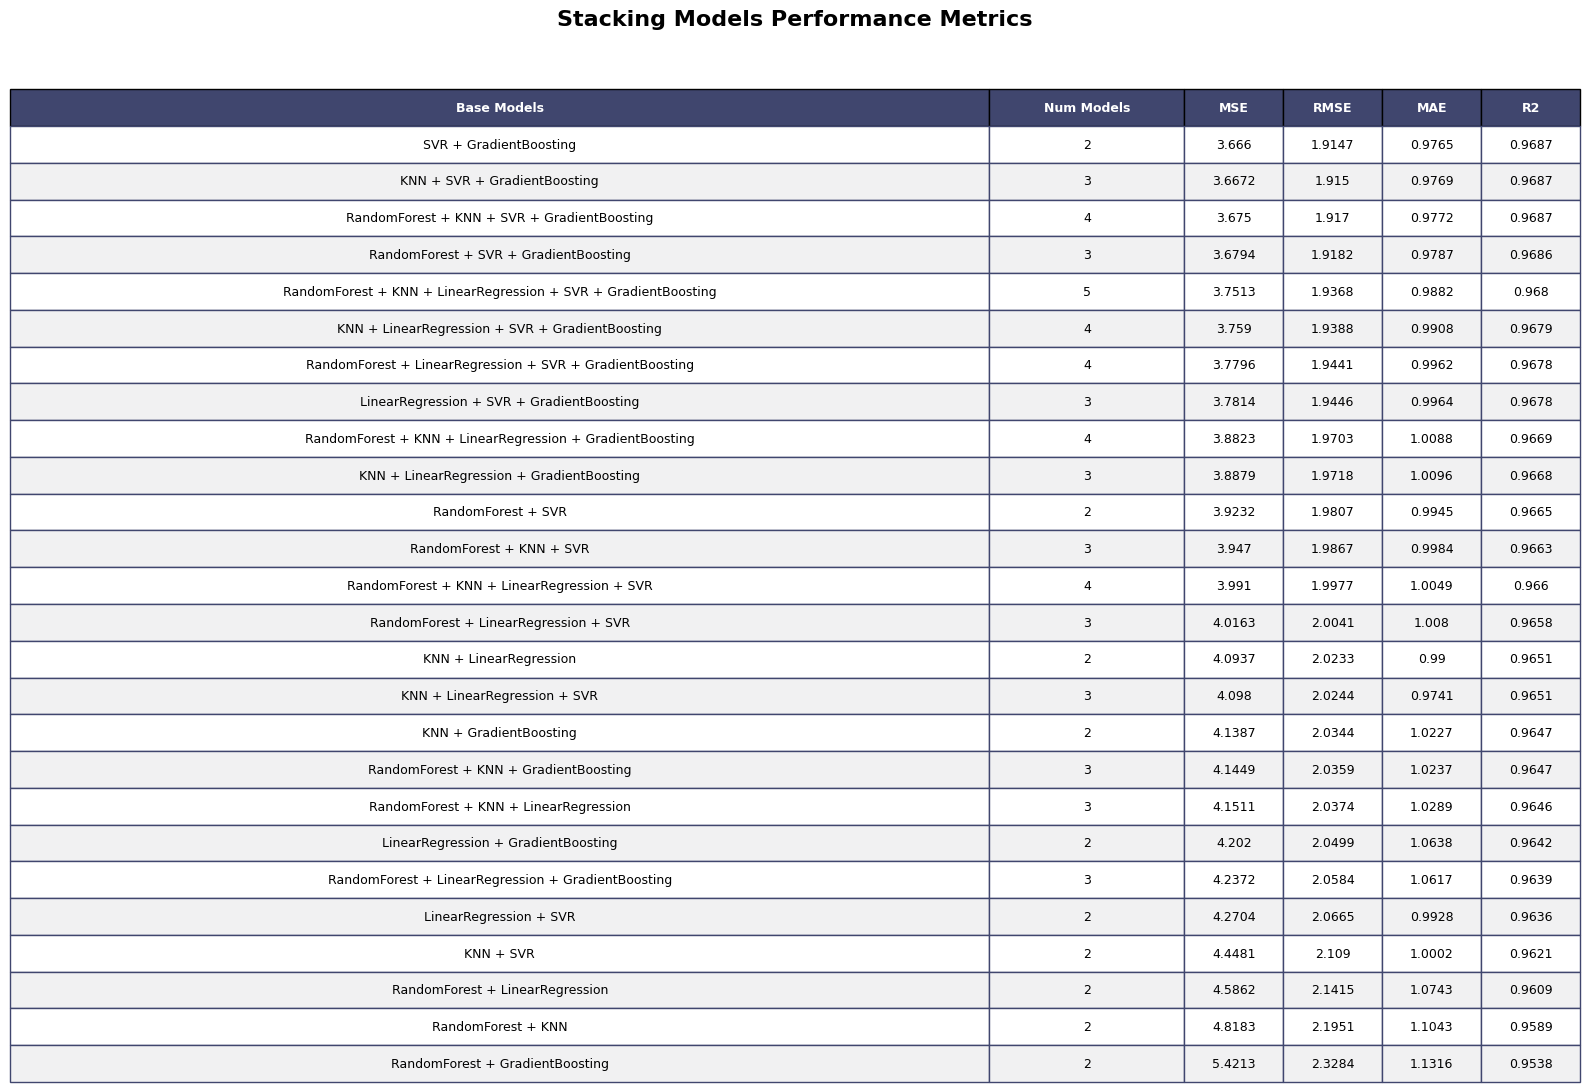

In [ ]:
optimized_models_retrain = {
    'RandomForest': rf_model_retrain,
    'KNN': knn_model_retrain,
    'LinearRegression': lr_model_retrain,
    'SVR': svr_model_retrain,
    'GradientBoosting': gb_model_retrain
}

meta_model = LinearRegression()
results_retrain = []
model_names_retrain = list(optimized_models_retrain.keys())

for r in range(2, len(model_names_retrain) + 1):
    for combo in itertools.combinations(model_names_retrain, r):
        estimators = [(name.lower(), optimized_models_retrain[name]) for name in combo]
        stacking = StackingRegressor(
            estimators=estimators,
            final_estimator=meta_model,
            n_jobs=-1
        )

        stacking.fit(X_train_retrain, y_train_retrain)
        preds = stacking.predict(X_test_retrain)

        mse = mean_squared_error(y_test_retrain, preds)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_test_retrain, preds)
        r2 = r2_score(y_test_retrain, preds)

        results_retrain.append({
            'Base Models': " + ".join(combo),
            'Num Models': len(combo),
            'MSE': mse,
            'RMSE': rmse,
            'MAE': mae,
            'R2': r2
        })

results_df_retrain = pd.DataFrame(results_retrain).sort_values(by='RMSE')
fig, ax = plt.subplots(figsize=(16, len(results_df_retrain) * 0.35 + 2))
ax.axis('off')

tbl = ax.table(
    cellText=results_df_retrain.round(4).values,
    colLabels=results_df_retrain.columns,
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 0.95]
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.auto_set_column_width(col=list(range(len(results_df_retrain.columns))))
for (i, j), cell in tbl.get_celld().items():
    cell.set_height(0.06)
    if i == 0:
        cell.set_facecolor('#40466e')
        cell.set_text_props(weight='bold', color='w')
    else:
        cell.set_facecolor('#f1f1f2' if i % 2 == 0 else 'white')
        cell.set_edgecolor('#40466e')

fig.suptitle("Stacking Models Performance Metrics", fontsize=16, weight='bold', y=0.98)
plt.tight_layout()
plt.show()

In order to optimize model performance and reduce redundancy, several features were excluded based on their relative importance, information overlap, and practical measurement considerations:

- Arsenic (As) and Cadmium (Cd): These variables were removed due to their limited influence on the predictive model.

- Ammonium (NH₄) and Nitrate (NO₃): Both features were excluded as their information is largely captured by Nitrite (NO₂), which exhibits a stronger effect on model performance.

- Biochemical Oxygen Demand (BOD): Although BOD demonstrates a higher predictive contribution than Chemical Oxygen Demand (COD), it was omitted because COD effectively encompasses the relevant information while being significantly faster to measure (BOD requires 5 days).

- Coliform: This feature was removed as its predictive content is already represented by E. coli, which offers better model performance.

This feature reduction strategy ensures the model is both efficient and interpretable, minimizing redundancy while maintaining predictive accuracy.

In [ ]:
stacking_model.fit(X_train_retrain, y_train_retrain)
sm_pred_retrain = stacking_model.predict(X_test_retrain)

In [ ]:
print("Stacking Model - MSE:", mean_squared_error(y_test_retrain, sm_pred_retrain))
print("Stacking Model - RMSE:", np.sqrt(mean_squared_error(y_test_retrain, sm_pred_retrain)))
print("Stacking Model - MAE:", mean_absolute_error(y_test_retrain, sm_pred_retrain))
print("Stacking Model - R^2:", r2_score(y_test_retrain, sm_pred_retrain))

Stacking Model - MSE: 3.7813773213295274
Stacking Model - RMSE: 1.9445763860876042
Stacking Model - MAE: 0.9964210669336558
Stacking Model - R^2: 0.9677565795352594


After retraining with a reduced feature set, the Stacking model exhibits slightly higher error metrics compared to the full-feature model, reflecting a minor reduction in predictive accuracy.

Despite this slight decrease in performance, the model still achieves high R² (0.957) and low error values, indicating that it remains reliable and acceptable for practical prediction tasks.

The feature reduction strategy provides a cost-efficient approach by eliminating variables that are either redundant or time-consuming to measure, without substantially compromising the model’s predictive capability.

Overall, the results demonstrate that careful feature selection can balance accuracy, efficiency, and practicality, making the reduced-feature Stacking model suitable for real-world applications.

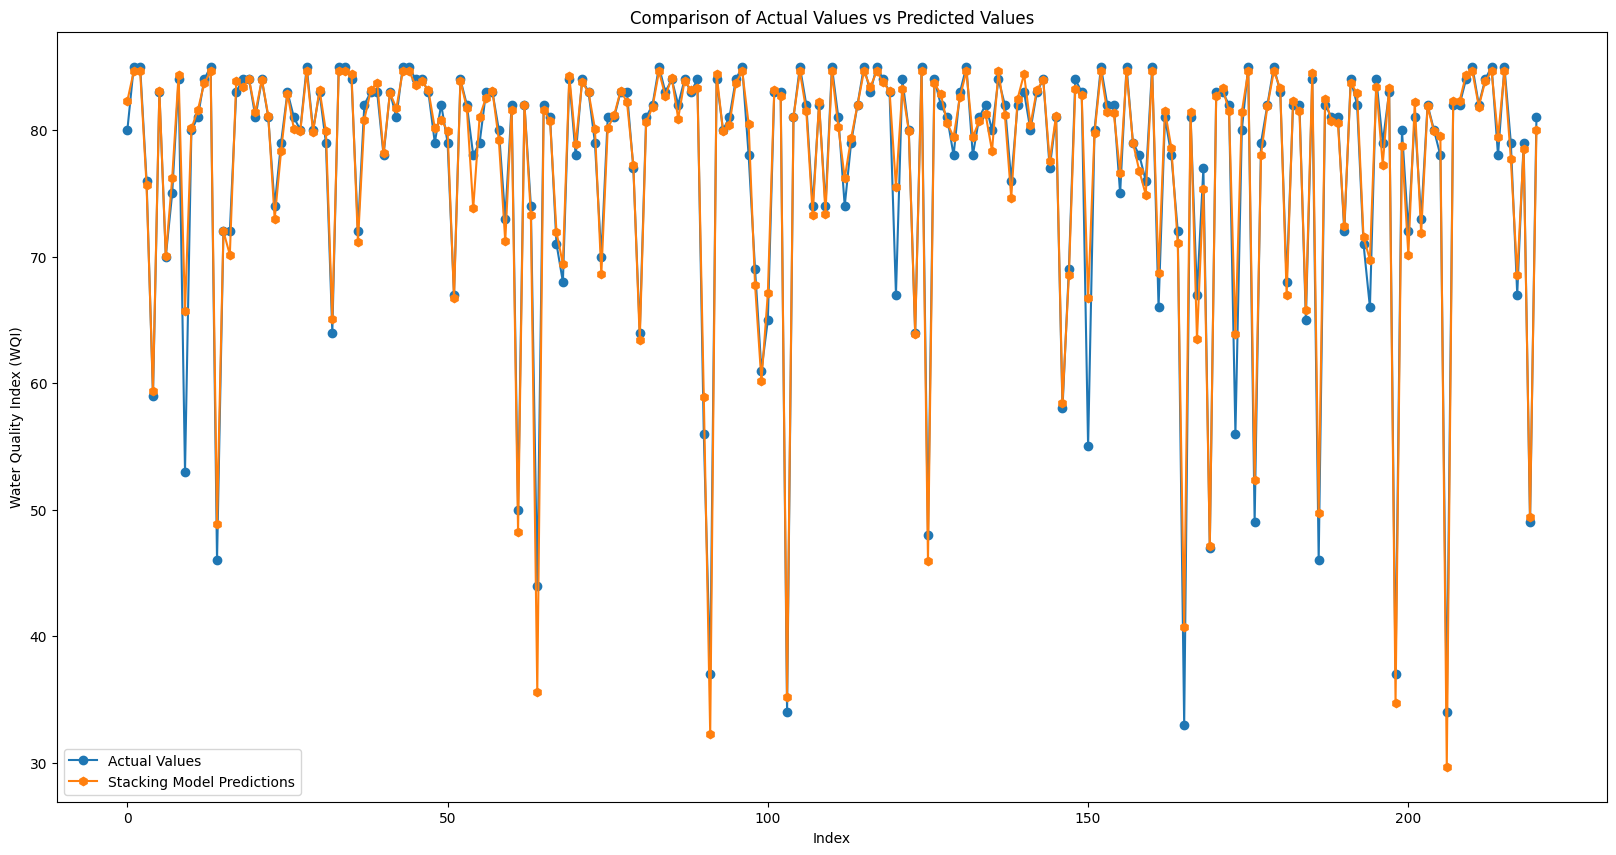

In [ ]:
plt.figure(figsize=(20, 10))
plt.plot(y_test_retrain.values, label='Actual Values', marker='o')
plt.plot(sm_pred_retrain, label='Stacking Model Predictions', marker='h')
plt.title('Comparison of Actual Values vs Predicted Values')
plt.xlabel('Index')
plt.ylabel('Water Quality Index (WQI)')
plt.legend()
plt.show()

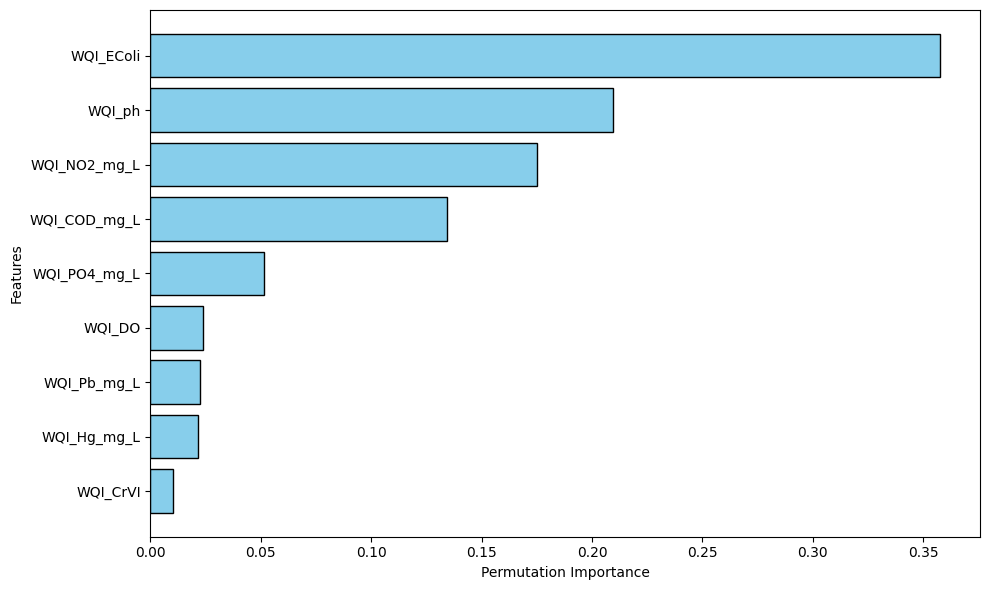

In [ ]:
# Calculate Permutation Importance
perm_importance = permutation_importance(stacking_model, X_test_retrain, y_test_retrain, n_repeats=30, random_state=42)

# Get the mean values and sort features by importance
sorted_idx = perm_importance.importances_mean.argsort()

# Plot the bar chart
plt.figure(figsize=(10, 6))
plt.barh(
    X_test_retrain.columns[sorted_idx], 
    perm_importance.importances_mean[sorted_idx], 
    color="skyblue", 
    edgecolor="black"
)
plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [ ]:
wqi_data_droped_v3 = final_data.copy()
wqi_data_droped_v3.drop({'EColi', 'COD_mg_L', 'NH4_mg_L', 'NO3_mg_L', 'Cd_mg_L', 'As_mg_L', 'VN_WQI'}, axis=1, inplace=True)
for metal, bp_points in metal_configs.items():
    if metal in wqi_data_droped_v3.columns:
        new_col_name = f'WQI_{metal.split()[0]}'
        wqi_data_droped_v3[new_col_name] = wqi_data_droped_v3[metal].apply(
            lambda x: calculate_wqi_generic(x, bp_points)
        )
wqi_data_droped_v3['WQI_DO'] = wqi_data_droped_v3.apply(
    lambda row: calculate_wqi_do(row['DO_mg_L'], row['Temperature_C']), axis=1
)
wqi_data_droped_v3['WQI_ph'] = wqi_data_droped_v3['pH'].apply(calculate_wqi_ph)
for param, bp_points in params_config.items():
    if param in wqi_data_droped_v3.columns:
        # Create a new column name, e.g., WQI_BOD5, WQI_NH4...
        new_col = f"WQI_{param.replace('+', '').replace('-', '')}"
        wqi_data_droped_v3[new_col] = wqi_data_droped_v3[param].apply(
            lambda x: calculate_wqi_formula1(x, bp_points)
        )

# 4. Handle NO2- separately (Because the table only has 2 levels: <=0.05 and >0.05)
if 'NO2_mg_L' in wqi_data_droped_v3.columns:
    wqi_data_droped_v3['WQI_NO2_mg_L'] = wqi_data_droped_v3['NO2_mg_L'].apply(
        lambda x: 100 if x <= 0.05 else 10 if x > 0.05 else np.nan
    )
wqi_data_droped_v3['VN_WQI'] = wqi_data_droped_v3.apply(calculate_final_vn_wqi, axis=1)

In [ ]:
y1 = wqi_data_droped_v3['VN_WQI']
y2 = final_data['VN_WQI']
print("Retrained Data - MSE:", mean_squared_error(y2, y1))
print("Retrained Data - RMSE:", np.sqrt(mean_squared_error(y2, y1)))
print("Retrained Data - MAE:", mean_absolute_error(y2, y1))
print("Retrained Data - R^2:", r2_score(y2, y1))

Retrained Data - MSE: 199.90735694822888
Retrained Data - RMSE: 14.138859817829331
Retrained Data - MAE: 13.97275204359673
Retrained Data - R^2: -0.5578467130338536


The recalculated WQI demonstrates that, while it is technically possible to compute the index with fewer parameters, the resulting values deviate substantially from the original full-parameter WQI.

The negative R² indicates a very poor fit compared to the original WQI, highlighting that the reduced-parameter index fails to accurately reflect the water quality profile.

This significant discrepancy underscores the sensitivity of the traditional WQI method to the inclusion of key parameters. Omitting certain variables severely compromises its reliability and interpretability.

In practical applications, although the recalculated WQI remains formally acceptable, it may mislead assessments or decision-making in water quality monitoring.

These results emphasize the advantage of machine learning–based approaches, such as the Stacking Ensemble model, which maintain high predictive accuracy and robustness even when some features are omitted, providing a more reliable alternative for water quality evaluation.

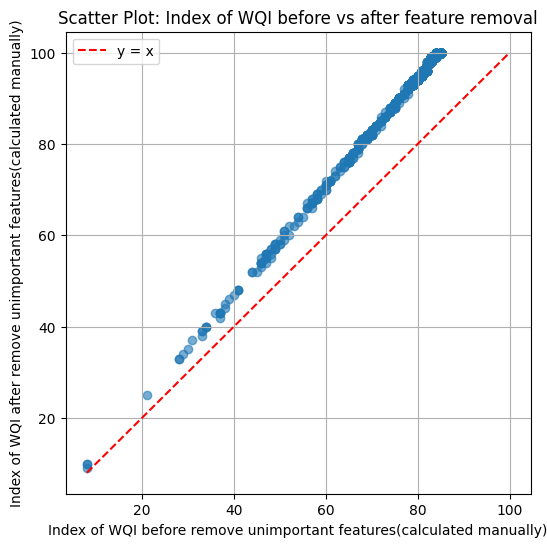

In [ ]:
manual_index = final_data['VN_WQI']
ml_index = wqi_data_droped_v3['VN_WQI']

plt.figure(figsize=(6, 6))
plt.scatter(manual_index, ml_index, alpha=0.6)

min_v = min(manual_index.min(), ml_index.min())
max_v = max(manual_index.max(), ml_index.max())
plt.plot([min_v, max_v], [min_v, max_v], 'r--', label='y = x')

plt.xlabel('Index of WQI before remove unimportant features(calculated manually)')
plt.ylabel('Index of WQI after remove unimportant features(calculated manually)')
plt.title('Scatter Plot: Index of WQI before vs after feature removal')
plt.legend()
plt.grid(True)
plt.show()

The scatter plot above compares the Water Quality Index (WQI) calculated using all original parameters against the WQI recalculated after removing unimportant features. The red dashed line represents the 1:1 line (y=x), where points would lie if the recalculated WQI perfectly matched the original full-parameter WQI.

- The scatter plot shows that most points lie above the 1:1 line, indicating that the recalculated WQI generally produces higher index values than the original WQI.

- The deviation from the 1:1 line is more pronounced at mid-range WQI values, suggesting that the reduction of features disproportionately inflates WQI scores for moderately polluted samples.

- Although the recalculated WQI remains formally valid and recognizable, this consistent upward shift highlights a systematic bias introduced by removing certain parameters.

- These results emphasize the sensitivity of the traditional WQI method to the inclusion of key water quality parameters and demonstrate the limitations of using a reduced subset for accurate water quality assessment.

- In practical terms, while WQI can still be computed with fewer parameters, the overestimation of water quality scores could mislead environmental assessments or decision-making if interpreted directly.